# Crop Pest and Disease Classification (CCMT): Traditional ML vs. Deep Learning

Classify a photo of a crop leaf into one of 22 crop-and-condition classes (for example `Maize_leaf_blight` or `Cassava_mosaic`), so that early diagnosis from a phone photo becomes possible for farmers and extension workers.

**Dataset.** CCMT, *Dataset for Crop Pest and Disease Detection* (Mendeley Data, DOI 10.17632/bwh3zbpkpv.1): leaf photos of cashew, cassava, maize and tomato collected on farms in Ghana. Only the raw images are used (25,220 files, 25,170 after removing unreadable ones). The pre-augmented images are not used.

**Approach.** Two paradigms are compared on the same stratified 70/15/15 split (seed 42):
- *Traditional ML (Scikit-Learn):* hand-crafted colour, texture and edge features, then Logistic Regression, SVM and Random Forest, with hyperparameter tuning.
- *Deep learning (TensorFlow/Keras, `tf.data` pipeline):* a small CNN trained from scratch (Sequential API), then MobileNetV2 transfer learning (Functional API) with a frozen base followed by fine-tuning.

## 1. Setup and configuration


In [ ]:
import os, json, random, time, pathlib, subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image, UnidentifiedImageError
from joblib import Parallel, delayed

from skimage.feature import hog, local_binary_pattern
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)


DRIVE_DIR = pathlib.Path('/content/drive/MyDrive/ccmt_project')
FIG_DIR   = DRIVE_DIR / 'figures'
for d in (DRIVE_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

ZIP_PATH = DRIVE_DIR / 'ccmt_raw.zip'
DATA_DIR = pathlib.Path('/content/ccmt')
ROOT     = DATA_DIR / 'Raw Data' / 'CCMT Dataset'

IMG_EXT          = ('.jpg', '.jpeg', '.png')
FEATURE_IMG_SIZE = 128

print('TensorFlow', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

Mounted at /content/drive
TensorFlow 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Data loading


In [ ]:
if ROOT.is_dir():
    print('Already extracted:', ROOT)
else:
    subprocess.run(['unzip', '-q', str(ZIP_PATH), '-d', str(DATA_DIR)], check=True)
    print('Extracted to', DATA_DIR)

Extracted to /content/ccmt


The folder layout is Crop/condition/image.jpg. Each image becomes one row with its path, crop, condition and a combined label of the form Crop_condition.

The combined label is necessary because healthy, leaf blight and leaf spot occur under more than one crop, so the condition alone would merge unrelated classes. The original folder spellings (gumosis, grasshoper, verticulium) are kept for traceability. The table is sorted by path so that row order does not depend on the filesystem.

In [ ]:
rows = []
for p in ROOT.rglob('*'):
    if p.suffix.lower() in IMG_EXT:
        crop, disease = p.parent.parent.name, p.parent.name
        rows.append({'path': str(p), 'crop': crop, 'disease': disease,
                     'label': f'{crop}_{disease}'.replace(' ', '_')})

df = pd.DataFrame(rows).sort_values('path').reset_index(drop=True)
print('Images:', len(df), '| Classes:', df['label'].nunique())
df.head()

Images: 25220 | Classes: 22


,path,crop,disease,label
0,/content/ccmt/Raw Data/CCMT Dataset/Cashew/ant...,Cashew,anthracnose,Cashew_anthracnose
1,/content/ccmt/Raw Data/CCMT Dataset/Cashew/ant...,Cashew,anthracnose,Cashew_anthracnose
2,/content/ccmt/Raw Data/CCMT Dataset/Cashew/ant...,Cashew,anthracnose,Cashew_anthracnose
3,/content/ccmt/Raw Data/CCMT Dataset/Cashew/ant...,Cashew,anthracnose,Cashew_anthracnose
4,/content/ccmt/Raw Data/CCMT Dataset/Cashew/ant...,Cashew,anthracnose,Cashew_anthracnose


Interpretation: The raw folder holds 25,220 images in 22 classes, which satisfies the 20,000-sample minimum. The dataset paper reports a slightly different total (24,881), so the difference is noted rather than hidden.

## Exploratory Data Analysis

In [ ]:
BAD_JSON = DRIVE_DIR / 'bad_files.json'

if BAD_JSON.exists():
    bad = json.load(open(BAD_JSON))
    print('Loaded cached list.')
else:
    bad = []
    for p in df['path']:
        try:
            with Image.open(p) as im:
                im.verify()
        except (UnidentifiedImageError, OSError, SyntaxError):
            bad.append(p)
    json.dump(bad, open(BAD_JSON, 'w'))

print('Unreadable files:', len(bad))
for p in bad[:10]:
    print(os.path.getsize(p), 'bytes |', p)

Loaded cached list.
Unreadable files: 50
59104 bytes | /content/ccmt/Raw Data/CCMT Dataset/Maize/healthy/healthy18_.jpg
45744 bytes | /content/ccmt/Raw Data/CCMT Dataset/Maize/healthy/healthy88_.jpg
30685 bytes | /content/ccmt/Raw Data/CCMT Dataset/Maize/leaf beetle/leaf beetle207_.jpg
29248 bytes | /content/ccmt/Raw Data/CCMT Dataset/Maize/leaf beetle/leaf beetle208_.jpg
20228 bytes | /content/ccmt/Raw Data/CCMT Dataset/Maize/leaf beetle/leaf beetle326_.jpg
38585 bytes | /content/ccmt/Raw Data/CCMT Dataset/Maize/leaf beetle/leaf beetle458_.jpg
31895 bytes | /content/ccmt/Raw Data/CCMT Dataset/Maize/leaf beetle/leaf beetle573_.jpg
30707 bytes | /content/ccmt/Raw Data/CCMT Dataset/Maize/leaf beetle/leaf beetle690_.jpg
49630 bytes | /content/ccmt/Raw Data/CCMT Dataset/Maize/leaf beetle/leaf beetle691_.jpg
34538 bytes | /content/ccmt/Raw Data/CCMT Dataset/Maize/leaf beetle/leaf beetle798_.jpg


df_clean is the dataset used from here on. The check on the smallest classes confirms that no class lost a noticeable share of its images.

In [ ]:
df_clean = df[~df['path'].isin(bad)].reset_index(drop=True)
print('Before:', len(df), '| After:', len(df_clean))
print(df_clean['label'].value_counts().sort_values().head(5))

Before: 25220 | After: 25170
label
Maize_healthy          206
Maize_fall_armyworm    285
Cashew_gumosis         392
Tomato_healthy         468
Tomato_leaf_curl       514
Name: count, dtype: int64


Interpretation: 25,220 images become 25,170 after cleaning. The smallest classes are barely affected (Maize_healthy 208 to 206 images).

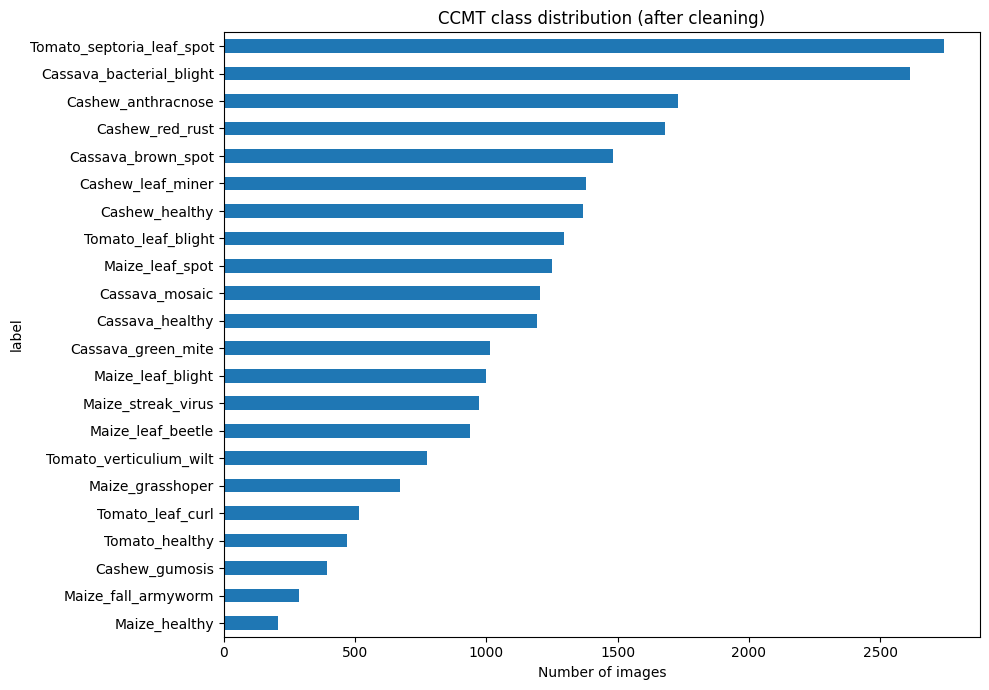

Imbalance ratio (max/min): 13.3
crop
Cashew     6549
Cassava    7508
Maize      5321
Tomato     5792
dtype: int64


In [ ]:
counts = df_clean['label'].value_counts()

plt.figure(figsize=(10, 7))
counts.sort_values().plot.barh()
plt.xlabel('Number of images'); plt.title('CCMT class distribution (after cleaning)')
plt.tight_layout()
plt.savefig(FIG_DIR / 'class_distribution.png', dpi=200)
plt.show()

print('Imbalance ratio (max/min): %.1f' % (counts.max() / counts.min()))
print(df_clean.groupby('crop').size())

Interpretation: The largest class is Tomato_septoria_leaf_spot (2,743 images) and the smallest is Maize_healthy (206), an imbalance of about 13:1. Maize_fall_armyworm and Cashew_gumosis are also small. Accuracy alone would therefore be misleading, so the evaluation uses macro-F1 and per-class precision and recall, and class weights are tested during training.

In [ ]:
sizes = []
for p in df_clean.sample(500, random_state=SEED)['path']:
    with Image.open(p) as im:
        sizes.append(im.size)
pd.Series(sizes).value_counts().head(10)

,count
"(400, 400)",499
"(355, 400)",1


Interpretation: In the sample, 499 of 500 images are 400×400 pixels and one is 324×239. Resizing to a fixed square size is therefore a plain downscale for nearly all images and a small distortion for the occasional non-square one.

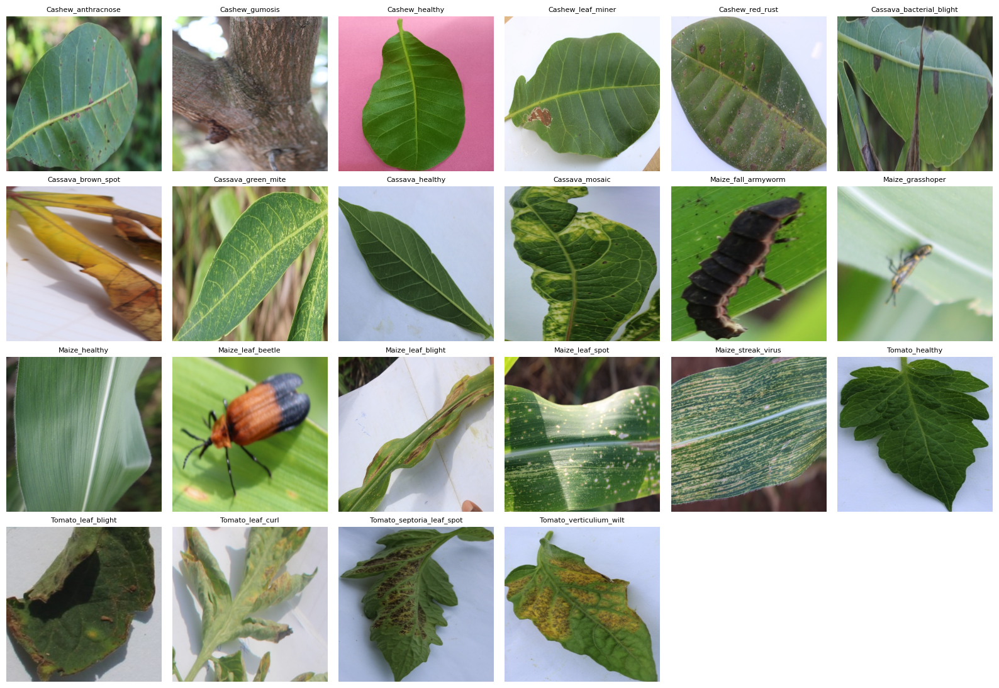

In [ ]:
fig, axes = plt.subplots(4, 6, figsize=(16, 11))
for ax, (label, grp) in zip(axes.ravel(), df_clean.groupby('label')):
    ax.imshow(Image.open(grp.sample(1, random_state=SEED)['path'].iloc[0]))
    ax.set_title(label, fontsize=8); ax.axis('off')
for ax in axes.ravel()[df_clean['label'].nunique():]:
    ax.axis('off')
plt.tight_layout()
plt.savefig(FIG_DIR / 'sample_per_class.png', dpi=200)
plt.show()

Observations: Add your own observations from the grid: background, lighting, and which classes look visually similar.

## Data Split, Label encoding and Class weights

In [ ]:
class_names = sorted(df_clean['label'].unique())
label2id = {c: i for i, c in enumerate(class_names)}
NUM_CLASSES = len(class_names)

SPLIT_FILES = {n: DRIVE_DIR / f'{n}.csv' for n in ('train', 'val', 'test')}

if all(f.exists() for f in SPLIT_FILES.values()):
    train_df, val_df, test_df = (pd.read_csv(SPLIT_FILES[n]) for n in ('train', 'val', 'test'))
    print('Loaded saved split.')
else:
    train_df, temp_df = train_test_split(
        df_clean, test_size=0.30, stratify=df_clean['label'], random_state=SEED)
    val_df, test_df = train_test_split(
        temp_df, test_size=0.50, stratify=temp_df['label'], random_state=SEED)
    for d in (train_df, val_df, test_df):
        d['y'] = d['label'].map(label2id)
    for n, d in zip(('train', 'val', 'test'), (train_df, val_df, test_df)):
        d.to_csv(SPLIT_FILES[n], index=False)
    print('Created and saved new split.')

for name, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    print(name, len(d))

Loaded saved split.
train 17619
val 3775
test 3776


The three sets contain 17,619, 3,775 and 3,776 images, which sum to the 25,170 cleaned images.

In [ ]:
dist = pd.DataFrame({
    'train': train_df['label'].value_counts(),
    'val':   val_df['label'].value_counts(),
    'test':  test_df['label'].value_counts()})
dist.sort_values('train')

,train,val,test
label,,,
Maize_healthy,144,31,31
Maize_fall_armyworm,199,43,43
Cashew_gumosis,274,59,59
Tomato_healthy,328,70,70
Tomato_leaf_curl,360,77,77
Maize_grasshoper,471,101,101
Tomato_verticulium_wilt,541,116,116
Maize_leaf_beetle,657,141,140
Maize_streak_virus,680,146,146


Weights are computed from the training set only and give rarer classes a larger weight during training.

In [ ]:
weights = compute_class_weight('balanced',
                               classes=np.arange(NUM_CLASSES),
                               y=train_df['y'])
class_weight = dict(enumerate(weights))

pd.Series(weights, index=class_names).round(2).sort_values(ascending=False).head(5)

,0
Maize_healthy,5.56
Maize_fall_armyworm,4.02
Cashew_gumosis,2.92
Tomato_healthy,2.44
Tomato_leaf_curl,2.22


## 5. Feature Engineering for traditional ML

### Feature extraction

In [ ]:
def extract_features(path, size=FEATURE_IMG_SIZE):
    bgr = cv2.imread(path)
    bgr = cv2.resize(bgr, (size, size), interpolation=cv2.INTER_AREA)

    # Colour: HSV histograms
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    hist = np.concatenate([
        cv2.calcHist([hsv], [c], None, [32], [0, 180 if c == 0 else 256]).ravel()
        for c in range(3)])
    hist = hist / hist.sum()
    pix = bgr.reshape(-1, 3) / 255.0
    color_stats = np.concatenate([pix.mean(0), pix.std(0)])

    # Texture uniform LBP histogram (10 bins)
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    lbp = local_binary_pattern(gray, P=8, R=1, method='uniform')
    lbp_hist = np.bincount(lbp.astype(int).ravel(), minlength=10) / lbp.size

    # Shape and edges: HOG
    hog_feat = hog(gray, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2))

    return np.concatenate([hist, color_stats, lbp_hist, hog_feat]).astype(np.float32)

Checks the output shape, the presence of NaNs and the time per image (about 0.056 s per image on one CPU core) before running the full extraction.

In [ ]:
t0 = time.time()
feats = np.stack([extract_features(p) for p in train_df['path'].iloc[:50]])
print('Feature matrix:', feats.shape)
print('Seconds per image:', round((time.time() - t0) / 50, 4))
print('Any NaN:', np.isnan(feats).any())

Feature matrix: (50, 1876)
Seconds per image: 0.0106
Any NaN: False


Each split is saved to Drive as a compressed .npz file; if the file exists it is loaded instead of recomputed.

In [ ]:
def build_features(split_df, name):
    out = DRIVE_DIR / f'features_{name}.npz'
    if out.exists():
        d = np.load(out)
        return d['X'], d['y']
    X = np.stack(Parallel(n_jobs=-1)(
        delayed(extract_features)(p) for p in split_df['path']))
    y = split_df['y'].values
    np.savez_compressed(out, X=X, y=y)
    return X, y

t0 = time.time()
X_train, y_train = build_features(train_df, 'train')
X_val,   y_val   = build_features(val_df,   'val')
X_test,  y_test  = build_features(test_df,  'test')

print('Done in', round((time.time() - t0) / 60, 1), 'min')
print(X_train.shape, X_val.shape, X_test.shape)
print('Any NaN:', any(np.isnan(a).any() for a in (X_train, X_val, X_test)))

Done in 0.1 min
(17619, 1876) (3775, 1876) (3776, 1876)
Any NaN: False


The feature matrices have shapes (17,619, 1,876), (3,775, 1,876) and (3,776, 1,876), with no missing values.

## 6. Traditional ML models

Three Scikit-Learn algorithms from different families (linear, kernel, tree ensemble) are trained on the 1,876 features and compared on the validation set. The test set stays untouched until Section 9.

Feature scaling: Logistic Regression and SVM are sensitive to feature scale, so they use standardised features. The scaler is fitted on the training set only. Tree-based models are unaffected by scale and use the raw features.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score
import joblib

MODEL_DIR = f'{DRIVE_DIR}/models'
os.makedirs(MODEL_DIR, exist_ok=True)

scaler = StandardScaler().fit(X_train)
Xs_train, Xs_val, Xs_test = (scaler.transform(a) for a in (X_train, X_val, X_test))
joblib.dump(scaler, f'{MODEL_DIR}/scaler.joblib')
print(Xs_train.shape, 'mean ~%.3f, std ~%.3f' % (Xs_train.mean(), Xs_train.std()))

(17619, 1876) mean ~-0.000, std ~1.000


`fit_and_score` fits a model (or loads it from Drive if already fitted), then records training accuracy, validation accuracy, validation macro-F1 and fit time, and appends them to a results table saved on Drive. Macro-F1 averages the F1 of all 22 classes equally, so it is the headline metric given the 13:1 imbalance. The gap between training and validation accuracy indicates overfitting.

In [ ]:
RESULTS_CSV = f'{DRIVE_DIR}/ml_baseline_results.csv'
results = pd.read_csv(RESULTS_CSV).to_dict('records') if os.path.exists(RESULTS_CSV) else []

def fit_and_score(name, model, Xtr, Xva):
    path = f'{MODEL_DIR}/baseline_{name}.joblib'
    old = next((r for r in results if r['model'] == name), None)
    if os.path.exists(path):
        model = joblib.load(path)
        fit_s = old['fit_seconds'] if old else None
        print(f'{name}: loaded saved model')
    else:
        t0 = time.time()
        model.fit(Xtr, y_train)
        fit_s = round(time.time() - t0, 1)
        joblib.dump(model, path)
        print(f'{name}: fitted in {fit_s} s')

    pred_val = model.predict(Xva)
    row = {
        'model': name,
        'train_acc': round(accuracy_score(y_train, model.predict(Xtr)), 4),
        'val_acc': round(accuracy_score(y_val, pred_val), 4),
        'val_macro_f1': round(f1_score(y_val, pred_val, average='macro'), 4),
        'fit_seconds': fit_s,
    }
    results[:] = [r for r in results if r['model'] != name] + [row]
    pd.DataFrame(results).to_csv(RESULTS_CSV, index=False)
    return row

### Baseline models
All use near-default settings with `class_weight='balanced'`. Each model runs in its own cell so that a slow or failed model does not lose the others.

**Logistic Regression** (linear baseline, scaled features):

In [ ]:
fit_and_score('logreg',
              LogisticRegression(max_iter=500, class_weight='balanced'),
              Xs_train, Xs_val)

logreg: fitted in 179.7 s


{'model': 'logreg',
 'train_acc': 0.9888,
 'val_acc': 0.5285,
 'val_macro_f1': 0.506,
 'fit_seconds': 179.7}

Interpretation: Training accuracy 0.989 against validation accuracy 0.529: the default regularisation (C=1) lets the model memorise the training set across 1,876 features. This is addressed by the C sweep in Section 6.6.

**Random Forest** (300 trees, raw features):

In [ ]:
fit_and_score('random_forest',
              RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                     n_jobs=-1, random_state=SEED),
              X_train, X_val)

random_forest: fitted in 443.1 s


{'model': 'random_forest',
 'train_acc': 0.9939,
 'val_acc': 0.6575,
 'val_macro_f1': 0.6379,
 'fit_seconds': 443.1}

**SVM** (RBF kernel, scaled features, default `C` and `gamma`; not tuned):

In [ ]:
fit_and_score('svm_rbf',
              SVC(kernel='rbf', class_weight='balanced', random_state=SEED),
              Xs_train, Xs_val)

svm_rbf: fitted in 675.3 s


{'model': 'svm_rbf',
 'train_acc': 0.8953,
 'val_acc': 0.5984,
 'val_macro_f1': 0.5934,
 'fit_seconds': 675.3}

### Baseline comparison
The models side by side, ranked by validation macro-F1.

In [ ]:
baseline_df = (pd.DataFrame(results)
                 .sort_values('val_macro_f1', ascending=False)
                 .reset_index(drop=True))
baseline_df

,model,train_acc,val_acc,val_macro_f1,fit_seconds
0,random_forest_tuned,0.9917,0.6967,0.6849,992.1
1,random_forest,0.9939,0.6575,0.6379,443.1
2,svm_rbf,0.8953,0.5984,0.5934,675.3
3,logreg_C0.01,0.7826,0.5385,0.5248,150.2
4,logreg_C0.1,0.9149,0.5412,0.5234,197.9
5,logreg,0.9888,0.5285,0.5060,179.7
6,logreg_C0.001,0.6355,0.5126,0.5040,88.6


Interpretation: The tuned Random Forest leads (validation macro-F1 0.685), followed by the SVM (0.593) and Logistic Regression (best 0.525 at C=0.01). All three show a large train-to-validation gap, which is a sign of high variance. About 60% validation accuracy is far above the roughly 4.5% expected from guessing among 22 classes, so the hand-crafted features carry real signal, but they plateau well below the deep models in Section 7.

### Error analysis of the baseline Random Forest
Per-class precision, recall and F1 on the validation set show where the classical model fails.

In [ ]:
from sklearn.metrics import classification_report

rf = joblib.load(f'{MODEL_DIR}/baseline_random_forest.joblib')
pred = rf.predict(X_val)
print(classification_report(y_val, pred, target_names=class_names, digits=3))

                           precision    recall  f1-score   support

       Cashew_anthracnose      0.774     0.699     0.734       259
           Cashew_gumosis      0.846     0.932     0.887        59
           Cashew_healthy      0.901     0.620     0.734       205
        Cashew_leaf_miner      0.760     0.646     0.698       206
          Cashew_red_rust      0.831     0.917     0.872       252
 Cassava_bacterial_blight      0.444     0.857     0.585       392
       Cassava_brown_spot      0.810     0.441     0.571       222
       Cassava_green_mite      0.755     0.691     0.722       152
          Cassava_healthy      0.860     0.821     0.840       179
           Cassava_mosaic      0.859     0.641     0.734       181
      Maize_fall_armyworm      0.850     0.395     0.540        43
         Maize_grasshoper      0.878     0.426     0.573       101
            Maize_healthy      0.792     0.613     0.691        31
        Maize_leaf_beetle      0.796     0.830     0.812     

Interpretation: Two large classes act as sinks: Cassava_bacterial_blight (precision 0.444, recall 0.857) and Tomato_septoria_leaf_spot (precision 0.510, recall 0.932) receive many images from other classes. Tomato_verticulium_wilt has precision 1.000 but recall 0.086, so the model almost never predicts it. Class size alone does not explain failure: Cashew_gumosis is small but scores F1 0.887.

**Most frequent confusions** (true class to predicted class):

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_val, pred)
np.fill_diagonal(cm, 0)
pairs = [(cm[i, j], class_names[i], class_names[j])
         for i in range(len(cm)) for j in range(len(cm)) if cm[i, j] > 0]
for n, true, pred_c in sorted(pairs, reverse=True)[:12]:
    print(f'{n:4d}  {true}  ->  {pred_c}')

 124  Tomato_leaf_blight  ->  Tomato_septoria_leaf_spot
  92  Tomato_verticulium_wilt  ->  Tomato_septoria_leaf_spot
  74  Cassava_brown_spot  ->  Cassava_bacterial_blight
  37  Tomato_leaf_curl  ->  Tomato_septoria_leaf_spot
  37  Cassava_mosaic  ->  Cassava_bacterial_blight
  35  Cashew_healthy  ->  Cassava_bacterial_blight
  34  Maize_leaf_spot  ->  Maize_leaf_blight
  34  Maize_grasshoper  ->  Cassava_bacterial_blight
  29  Maize_leaf_spot  ->  Cassava_bacterial_blight
  29  Maize_leaf_blight  ->  Maize_leaf_spot
  27  Maize_streak_virus  ->  Cassava_bacterial_blight
  27  Cassava_green_mite  ->  Cassava_bacterial_blight


Interpretation: The largest confusions send other tomato diseases into Tomato_septoria_leaf_spot (124 from leaf blight, 92 from verticulium wilt), and several cassava, cashew and maize classes into Cassava_bacterial_blight. The second pattern crosses crop boundaries, which the next cell quantifies.

**Crop-level error analysis**. How many errors send an image to the wrong crop, as opposed to the wrong condition within the right crop?

In [ ]:
crop_of = {i: c.split('_')[0] for i, c in enumerate(class_names)}
true_crop = np.array([crop_of[i] for i in y_val])
pred_crop = np.array([crop_of[i] for i in pred])

wrong = pred != y_val
cross = true_crop != pred_crop
print('Total errors:', wrong.sum())
print('Cross-crop errors: %d (%.1f%% of all errors)' % (cross.sum(), 100 * cross.sum() / wrong.sum()))
print('Crop-level accuracy: %.3f' % (true_crop == pred_crop).mean())
print(pd.crosstab(true_crop, pred_crop))

Total errors: 1293
Cross-crop errors: 519 (40.1% of all errors)
Crop-level accuracy: 0.863
col_0    Cashew  Cassava  Maize  Tomato
row_0                                  
Cashew      831      104      8      38
Cassava      27     1013     15      71
Maize        29      164    591      16
Tomato        6       41      0     821


Interpretation: 519 of the 1,293 validation errors (40.1%) cross crop boundaries, and crop-level accuracy is 0.863. For example, 164 of 800 maize images were predicted as cassava. Colour, texture and edge statistics do not reliably capture which crop is in the photo. This is compared with the deep model in Section 8.1.

### Hyperparameter tuning

**Random Forest: randomised search.** Ten random configurations of `max_features`, `min_samples_leaf`, `max_depth` and `class_weight` are trained on the training set and scored by macro-F1 on the fixed validation set (a predefined split instead of cross-validation, which would be too slow). `refit=False` prevents scikit-learn from refitting on training plus validation data. The search uses 100 trees to save time.

Best configuration: `min_samples_leaf=4`, `max_features=0.05`, `max_depth=None`, `class_weight='balanced'`, with validation macro-F1 0.6567 at 100 trees. The search took about 25 minutes.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, PredefinedSplit

X_tv = np.vstack([X_train, X_val])
y_tv = np.concatenate([y_train, y_val])
ps = PredefinedSplit(np.r_[np.full(len(y_train), -1), np.zeros(len(y_val))])

param_dist = {
    'max_features': ['sqrt', 'log2', 0.05],
    'min_samples_leaf': [1, 2, 4, 8],
    'max_depth': [None, 20, 40],
    'class_weight': ['balanced', 'balanced_subsample'],
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED),
    param_dist, n_iter=10, scoring='f1_macro', cv=ps,
    refit=False, random_state=SEED, verbose=2)

t0 = time.time()
rf_search.fit(X_tv, y_tv)
print('Search took', round((time.time() - t0) / 60, 1), 'min')
print('Best params:', rf_search.best_params_)
print('Best val macro-F1 (100 trees): %.4f' % rf_search.best_score_)

pd.DataFrame(rf_search.cv_results_)[['params', 'mean_test_score', 'mean_fit_time']] \
  .sort_values('mean_test_score', ascending=False) \
  .to_csv(f'{DRIVE_DIR}/rf_search_results.csv', index=False)

Fitting 1 folds for each of 10 candidates, totalling 10 fits
[CV] END class_weight=balanced, max_depth=None, max_features=log2, min_samples_leaf=1; total time=  28.9s
[CV] END class_weight=balanced_subsample, max_depth=40, max_features=sqrt, min_samples_leaf=4; total time= 1.6min
[CV] END class_weight=balanced, max_depth=20, max_features=log2, min_samples_leaf=4; total time=  23.4s
[CV] END class_weight=balanced, max_depth=None, max_features=sqrt, min_samples_leaf=1; total time= 1.8min
[CV] END class_weight=balanced, max_depth=40, max_features=log2, min_samples_leaf=1; total time=  28.6s
[CV] END class_weight=balanced_subsample, max_depth=20, max_features=sqrt, min_samples_leaf=4; total time= 1.6min
[CV] END class_weight=balanced, max_depth=None, max_features=0.05, min_samples_leaf=4; total time= 3.3min
[CV] END class_weight=balanced, max_depth=40, max_features=0.05, min_samples_leaf=4; total time= 3.4min
[CV] END class_weight=balanced, max_depth=20, max_features=sqrt, min_samples_leaf

Refit of the winning configuration at 300 trees, on the training set only:

In [ ]:
fit_and_score('random_forest_tuned',
              RandomForestClassifier(n_estimators=300, n_jobs=-1,
                                     random_state=SEED, **rf_search.best_params_),
              X_train, X_val)

random_forest_tuned: fitted in 992.1 s


{'model': 'random_forest_tuned',
 'train_acc': 0.9917,
 'val_acc': 0.6967,
 'val_macro_f1': 0.6849,
 'fit_seconds': 992.1}

Interpretation: At the same 300 trees, tuning raised validation macro-F1 from 0.638 to 0.685 and accuracy from 0.658 to 0.697, a like-for-like gain of about 0.05. The train-to-validation accuracy gap shrank from 0.34 to 0.30 but remains large: the forest is limited by its features, not by its settings.

**Logistic Regression: regularisation sweep** over `C`. Smaller `C` means stronger regularisation.

In [ ]:
for C in [0.001, 0.01, 0.1]:
    fit_and_score(f'logreg_C{C}',
                  LogisticRegression(C=C, max_iter=500, class_weight='balanced'),
                  Xs_train, Xs_val)

logreg_C0.001: fitted in 88.6 s
logreg_C0.01: fitted in 150.2 s
logreg_C0.1: fitted in 197.9 s


Interpretation: The sweep shows the usual U-shape. Stronger regularisation shrinks the train-to-validation gap (train accuracy 0.989 at C=1, 0.783 at C=0.01) and slightly improves validation macro-F1 (0.506 to 0.525). At C=0.001 the model underfits (train accuracy 0.636, macro-F1 0.504). The linear model stays well below the Random Forest.

**Combined results of all traditional-ML runs:**

In [ ]:
pd.DataFrame(results).sort_values('val_macro_f1', ascending=False).reset_index(drop=True)

,model,train_acc,val_acc,val_macro_f1,fit_seconds
0,random_forest_tuned,0.9917,0.6967,0.6849,992.1
1,random_forest,0.9939,0.6575,0.6379,443.1
2,svm_rbf,0.8953,0.5984,0.5934,675.3
3,logreg_C0.01,0.7826,0.5385,0.5248,150.2
4,logreg_C0.1,0.9149,0.5412,0.5234,197.9
5,logreg,0.9888,0.5285,0.5060,179.7
6,logreg_C0.001,0.6355,0.5126,0.5040,88.6


The tuned Random Forest is the best traditional model (validation macro-F1 0.685). The SVM was run at default settings only, so its lower score does not show that the algorithm is worse in general.

## 7. Deep learning models

### Restore state on the GPU runtime
Switching from a CPU to a GPU runtime resets the Colab session. This cell remounts Drive, re-extracts the images if needed and reloads the split files and class weights. Features and sklearn models are not needed from here on

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, random, time, subprocess, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
DRIVE_DIR = '/content/drive/MyDrive/ccmt_project'
ZIP_PATH = f'{DRIVE_DIR}/ccmt_raw.zip'

if not os.path.isdir('/content/ccmt/Raw Data'):
    subprocess.run(['unzip', '-q', ZIP_PATH, '-d', '/content/ccmt'], check=True)

train_df = pd.read_csv(f'{DRIVE_DIR}/train.csv')
val_df   = pd.read_csv(f'{DRIVE_DIR}/val.csv')
test_df  = pd.read_csv(f'{DRIVE_DIR}/test.csv')

class_names = sorted(train_df['label'].unique())
NUM_CLASSES = len(class_names)
class_weight = dict(enumerate(compute_class_weight(
    'balanced', classes=np.arange(NUM_CLASSES), y=train_df['y'])))

print(len(train_df), len(val_df), len(test_df), NUM_CLASSES)
print('GPU:', tf.config.list_physical_devices('GPU'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
17619 3775 3776 22
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
all_df = pd.concat([train_df.assign(split='train'),
                    val_df.assign(split='val'),
                    test_df.assign(split='test')], ignore_index=True)

tf_bad = []
for p, s in zip(all_df['path'], all_df['split']):
    try:
        tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)
    except tf.errors.InvalidArgumentError:
        tf_bad.append((s, p))

bad_df = pd.DataFrame(tf_bad, columns=['split', 'path'])
bad_df.to_csv(f'{DRIVE_DIR}/tf_decode_failures.csv', index=False)

print(len(bad_df), 'images fail TensorFlow decoding')
print(bad_df['split'].value_counts())
print(all_df.set_index('path').loc[bad_df['path'], 'label'].value_counts())

46 images fail TensorFlow decoding
split
train    31
val       9
test      6
Name: count, dtype: int64
label
Maize_leaf_spot            10
Maize_leaf_blight           8
Maize_streak_virus          7
Tomato_leaf_blight          6
Maize_leaf_beetle           6
Tomato_leaf_curl            4
Maize_healthy               2
Tomato_healthy              2
Tomato_verticulium_wilt     1
Name: count, dtype: int64


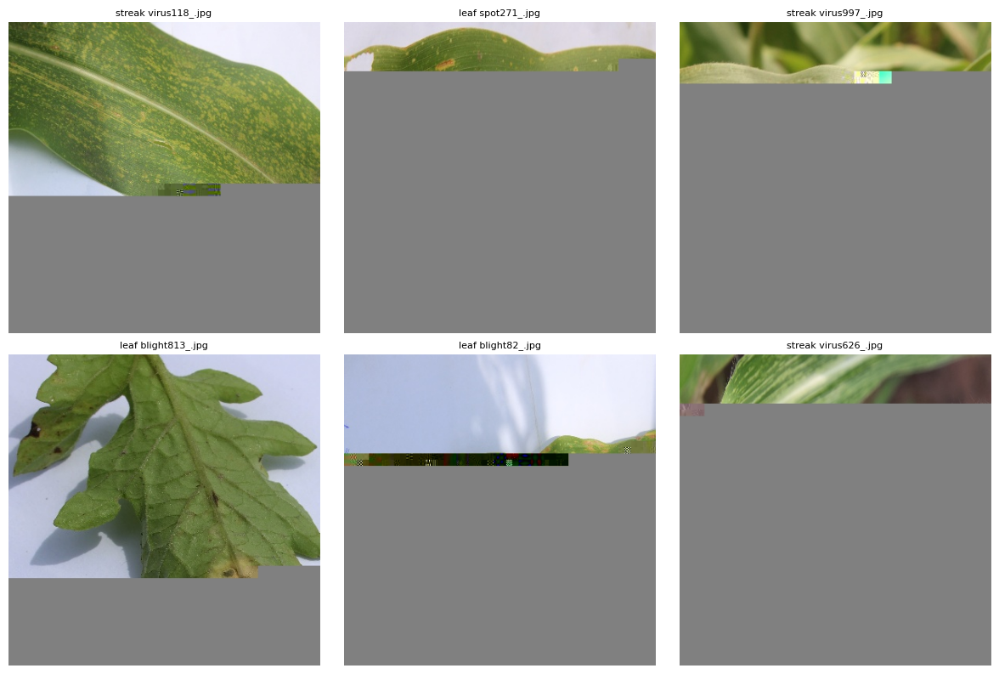

In [ ]:
import cv2

sample = bad_df.sample(6, random_state=SEED)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, p in zip(axes.ravel(), sample['path']):
    ax.imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB))
    ax.set_title(os.path.basename(p), fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

**Pipeline**: The splits are kept unchanged so that the deep models and the Random Forest are scored on identical images. Images are therefore read with OpenCV (which tolerates these files) inside tf.numpy_function, resized to 224×224 and stored as uint8. The decoded images are cached on local disk after the first pass, the training set is shuffled with a 2,000-image buffer, and batches of 32 are prefetched. Augmentation is applied inside the models as Keras layers, active only during training.

In [ ]:
import cv2, shutil

IMG_SIZE = 224
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

shutil.rmtree('/content/tfcache', ignore_errors=True)
os.makedirs('/content/tfcache', exist_ok=True)

def _read_resize(path):
    img = cv2.imread(path.decode('utf-8'))
    if img is None:
        raise ValueError(f'Cannot read {path}')
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)

def load_img(path, label):
    img = tf.numpy_function(_read_resize, [path], tf.uint8)
    img.set_shape((IMG_SIZE, IMG_SIZE, 3))
    return img, label

def make_ds(split_df, name, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (split_df['path'].values, split_df['y'].values.astype('int32')))
    ds = ds.map(load_img, num_parallel_calls=AUTOTUNE)
    ds = ds.cache(f'/content/tfcache/{name}')
    if training:
        ds = ds.shuffle(2000, seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(train_df, 'train', training=True)
val_ds   = make_ds(val_df,   'val')
test_ds  = make_ds(test_df,  'test')

images, labels = next(iter(train_ds))
print(images.shape, images.dtype, labels.shape)

(32, 224, 224, 3) <dtype: 'uint8'> (32,)


### Baseline CNN (Sequential API)
A small CNN trained from scratch: augmentation layers (random flips, rotation, zoom, contrast), rescaling, four convolution blocks (Conv, BatchNorm, ReLU, MaxPool with 32, 64, 128 and 128 filters), global average pooling, two dropout layers (0.4 and 0.3) and a dense head with softmax. The Sequential API fits because the data flows through a plain stack of layers. Global average pooling keeps the model small (261,238 parameters), which limits overfitting. Loss is sparse categorical cross-entropy because labels are integers.

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

def conv_block(filters):
    return [
        layers.Conv2D(filters, 3, padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.MaxPooling2D(),
    ]

cnn = keras.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),

    layers.Rescaling(1. / 255),

    *conv_block(32),
    *conv_block(64),
    *conv_block(128),
    *conv_block(128),

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.4),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation='softmax'),
], name='baseline_cnn')

cnn.compile(optimizer=keras.optimizers.Adam(1e-3),
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'])
cnn.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 224, 224, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             

 Total params: 261,238 (1020.46 KB)

 Trainable params: 260,534 (1017.71 KB)

 Non-trainable params: 704 (2.75 KB)

In [ ]:
import json
TB_DIR = f'{DRIVE_DIR}/tb_logs'

def tb_callback(run_name):
    return keras.callbacks.TensorBoard(log_dir=f'{TB_DIR}/{run_name}')

def log_scalars(run_name, metrics, hparams):
    w = tf.summary.create_file_writer(f'{TB_DIR}/{run_name}')
    with w.as_default():
        for k, v in metrics.items():
            tf.summary.scalar(k, float(v), step=0)
        tf.summary.text('hyperparameters', json.dumps(hparams, indent=2), step=0)
    w.close()

The classical-ML runs and the first CNN run were trained before logging was set up. This cell writes their saved metrics and hyperparameters to TensorBoard after the fact, from the results table and history file that were saved at training time. These are therefore post-hoc logs of real results, not live logs. The folder dl_cnn_baseline holds CNN run 1 (verified in Section 7.6).

In [ ]:
ml = pd.read_csv(f'{DRIVE_DIR}/ml_baseline_results.csv')
ml_params = {
  'logreg':        {'C': 1.0,   'max_iter': 500, 'class_weight': 'balanced'},
  'logreg_C0.001': {'C': 0.001, 'max_iter': 500, 'class_weight': 'balanced'},
  'logreg_C0.01':  {'C': 0.01,  'max_iter': 500, 'class_weight': 'balanced'},
  'logreg_C0.1':   {'C': 0.1,   'max_iter': 500, 'class_weight': 'balanced'},
  'svm_rbf':       {'kernel': 'rbf', 'C': 1.0, 'gamma': 'scale', 'class_weight': 'balanced'},
  'random_forest': {'n_estimators': 300, 'max_features': 'sqrt', 'class_weight': 'balanced'},
  'random_forest_tuned': {'n_estimators': 300, 'min_samples_leaf': 4, 'max_features': 0.05,
                          'max_depth': None, 'class_weight': 'balanced'},
}
for _, r in ml.iterrows():
    log_scalars(f"ml_{r['model']}",
                {k: r[k] for k in ['train_acc', 'val_acc', 'val_macro_f1', 'fit_seconds']},
                ml_params[r['model']])

h = pd.read_csv(f'{DRIVE_DIR}/cnn_baseline_history.csv')
w = tf.summary.create_file_writer(f'{TB_DIR}/dl_cnn_baseline')
with w.as_default():
    for epoch, row in h.iterrows():
        for k in ['accuracy', 'loss', 'val_accuracy', 'val_loss']:
            tf.summary.scalar(f'epoch_{k}', float(row[k]), step=epoch)
    tf.summary.text('hyperparameters', json.dumps(
        {'optimizer': 'Adam', 'lr': 1e-3, 'batch': 32, 'epochs': 30, 'dropout': [0.4, 0.3],
         'class_weight': 'balanced', 'augmentation': 'flip/rotate/zoom/contrast'}, indent=2), step=0)
w.close()

### Training the baseline CNN (run 2)
Adam (learning rate 1e-3), batch size 32, up to 30 epochs, class weights, early stopping (patience 6), learning-rate reduction on plateau and a checkpoint on the lowest validation loss. The CNN was trained twice with identical settings: run 1 (validation accuracy 0.747, macro-F1 0.737) and run 2, recorded below. Run 1's weights were overwritten by run 2, so its results are reported from the output observed at the time and its per-epoch history is preserved in the TensorBoard logs. This cell's logs were originally written under a different folder name and renamed afterwards (see the bookkeeping cell in Section 7.6).

In [ ]:
MODEL_DIR = f'{DRIVE_DIR}/models'
os.makedirs(MODEL_DIR, exist_ok=True)

callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=6,
                                  restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3),
    keras.callbacks.ModelCheckpoint(f'{MODEL_DIR}/cnn_baseline_best.keras',
                                    monitor='val_loss', save_best_only=True),
    tb_callback('dl_mobilenetv2_head'),
]

t0 = time.time()
history = cnn.fit(train_ds, validation_data=val_ds,
                  epochs=30, class_weight=class_weight,
                  callbacks=callbacks)
print('Training took', round((time.time() - t0) / 60, 1), 'min')

hist_df = pd.DataFrame(history.history)
hist_df.to_csv(f'{DRIVE_DIR}/cnn_baseline_history.csv', index=False)
hist_df.round(4).tail()

Epoch 1/30
551/551 ━━━━━━━━━━━━━━━━━━━━ 111s 167ms/step - accuracy: 0.1892 - loss: 2.5206 - val_accuracy: 0.1905 - val_loss: 2.5441 - learning_rate: 0.0010
Epoch 2/30
551/551 ━━━━━━━━━━━━━━━━━━━━ 74s 132ms/step - accuracy: 0.2804 - loss: 2.1187 - val_accuracy: 0.1113 - val_loss: 3.7491 - learning_rate: 0.0010
Epoch 3/30
551/551 ━━━━━━━━━━━━━━━━━━━━ 74s 132ms/step - accuracy: 0.3254 - loss: 1.9193 - val_accuracy: 0.2625 - val_loss: 2.7124 - learning_rate: 0.0010
Epoch 4/30
551/551 ━━━━━━━━━━━━━━━━━━━━ 73s 132ms/step - accuracy: 0.3684 - loss: 1.7726 - val_accuracy: 0.2342 - val_loss: 2.8283 - learning_rate: 0.0010
Epoch 5/30
551/551 ━━━━━━━━━━━━━━━━━━━━ 73s 132ms/step - accuracy: 0.4151 - loss: 1.5981 - val_accuracy: 0.4604 - val_loss: 1.5357 - learning_rate: 5.0000e-04
Epoch 6/30
551/551 ━━━━━━━━━━━━━━━━━━━━ 73s 131ms/step - accuracy: 0.4361 - loss: 1.5089 - val_accuracy: 0.3658 - val_loss: 2.0760 - learning_rate: 5.0000e-04
Epoch 7/30
551/551 ━━━━━━━━━━━━━━━━━━━━ 73s 132ms/step - accu

,accuracy,loss,val_accuracy,val_loss,learning_rate
25,0.6373,0.8914,0.7028,0.8288,0.0001
26,0.6381,0.8831,0.6977,0.8210,0.0001
27,0.6448,0.8742,0.7001,0.8481,0.0001
28,0.6457,0.8763,0.6795,0.9116,0.0001
29,0.6458,0.8647,0.6935,0.8786,0.0001


Training took 37.6 minutes for the full 30 epochs. Early stopping never triggered: validation loss was still improving slowly at the epoch limit.

### Evaluating the CNN
The best checkpoint (lowest validation loss, epoch 26) is reloaded and scored on the validation set.

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

best_epoch = hist_df['val_loss'].idxmin()
print('Lowest val_loss at epoch %d: val_loss %.4f, val_acc %.4f' % (
    best_epoch, hist_df.loc[best_epoch, 'val_loss'], hist_df.loc[best_epoch, 'val_accuracy']))

cnn_best = keras.models.load_model(f'{MODEL_DIR}/cnn_baseline_best.keras')
probs_val = cnn_best.predict(val_ds)
pred_cnn = probs_val.argmax(1)
y_val_true = val_df['y'].values

print('val acc %.4f | val macro-F1 %.4f' % (
    accuracy_score(y_val_true, pred_cnn),
    f1_score(y_val_true, pred_cnn, average='macro')))
print(classification_report(y_val_true, pred_cnn, target_names=class_names, digits=3))

Lowest val_loss at epoch 26: val_loss 0.8210, val_acc 0.6977
118/118 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step
val acc 0.6977 | val macro-F1 0.6959
                           precision    recall  f1-score   support

       Cashew_anthracnose      0.640     0.734     0.683       259
           Cashew_gumosis      0.918     0.949     0.933        59
           Cashew_healthy      0.722     0.863     0.787       205
        Cashew_leaf_miner      0.691     0.835     0.756       206
          Cashew_red_rust      0.988     0.964     0.976       252
 Cassava_bacterial_blight      0.852     0.513     0.640       392
       Cassava_brown_spot      0.588     0.856     0.697       222
       Cassava_green_mite      0.778     0.901     0.835       152
          Cassava_healthy      0.797     0.966     0.874       179
           Cassava_mosaic      0.904     0.834     0.868       181
      Maize_fall_armyworm      0.552     0.744     0.634        43
         Maize_grasshoper      0.677     0.832     0.74

Interpretation: Run 2 reaches validation accuracy 0.698 and macro-F1 0.696, against 0.747 and 0.737 for run 1 with the same settings. The roughly 4-point difference between two identical runs is a measure of run-to-run variance in deep learning and means that single-run differences of that size should not be treated as findings. The error pattern is stable across both runs: small classes have high recall but low precision, and the tomato diseases are weakest.

In [ ]:
import shutil
shutil.copy(f'{MODEL_DIR}/cnn_baseline_best.keras', f'{MODEL_DIR}/cnn_baseline_run2.keras')
shutil.copy(f'{DRIVE_DIR}/cnn_baseline_history.csv', f'{DRIVE_DIR}/cnn_baseline_run2_history.csv')

src = f'{TB_DIR}/dl_mobilenetv2_head'
dst = f'{TB_DIR}/dl_cnn_baseline_run2'
if os.path.isdir(src) and not os.path.exists(dst):
    os.rename(src, dst)
print(sorted(os.listdir(TB_DIR)))

['dl_cnn_baseline', 'dl_cnn_baseline_run2', 'ml_logreg', 'ml_logreg_C0.001', 'ml_logreg_C0.01', 'ml_logreg_C0.1', 'ml_random_forest', 'ml_random_forest_tuned', 'ml_svm_rbf']


In [ ]:
from tensorboard.backend.event_processing import event_accumulator
ea = event_accumulator.EventAccumulator(f'{TB_DIR}/dl_cnn_baseline',
                                        size_guidance={'tensors': 0})
ea.Reload()
print(ea.Tags()['tensors'])

v = ea.Tensors('epoch_val_accuracy')
vals = [float(tf.make_ndarray(e.tensor_proto)) for e in v]
print(len(vals), 'epochs logged | last val_accuracy = %.4f' % vals[-1])

['epoch_accuracy', 'epoch_loss', 'epoch_val_accuracy', 'epoch_val_loss', 'hyperparameters']
30 epochs logged | last val_accuracy = 0.7465


Interpretation: 30 epochs are logged and the last validation accuracy is 0.7465, so the folder holds run 1 and its per-epoch history is preserved. The weights of run 1 were not retained.

**Learning curves of the baseline CNN (run 2).**

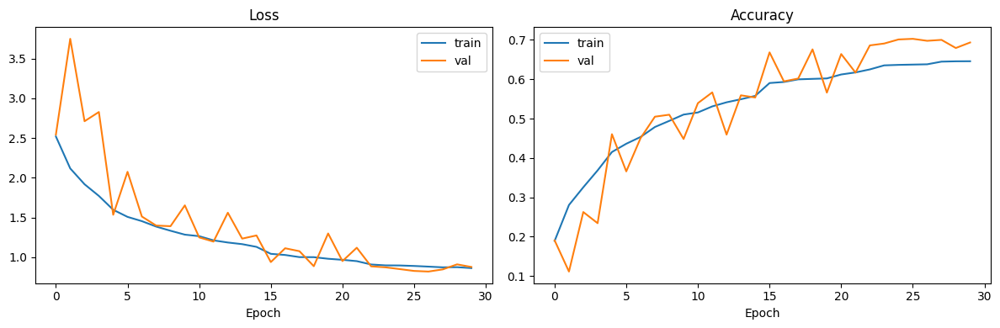

In [ ]:
h2 = pd.read_csv(f'{DRIVE_DIR}/cnn_baseline_run2_history.csv')
os.makedirs(f'{DRIVE_DIR}/figures', exist_ok=True)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h2['loss'], label='train'); ax[0].plot(h2['val_loss'], label='val')
ax[0].set_title('Loss'); ax[0].set_xlabel('Epoch'); ax[0].legend()
ax[1].plot(h2['accuracy'], label='train'); ax[1].plot(h2['val_accuracy'], label='val')
ax[1].set_title('Accuracy'); ax[1].set_xlabel('Epoch'); ax[1].legend()
plt.tight_layout()
plt.savefig(f'{DRIVE_DIR}/figures/cnn_baseline_run2_curves.png', dpi=200)
plt.show()

Interpretation: Training and validation curves never diverge, and validation accuracy sits above training accuracy from about epoch 15. Training accuracy is measured with augmentation and dropout active, while validation is clean, so this is the signature of underfitting (high bias): a small model under heavy regularisation. Validation is very noisy for the first 20 epochs (loss spiking to about 3.7 at epoch 2) and settles after the learning rate has been reduced. By epoch 30 the curves are close to a plateau but still sloping down slightly.

### Transfer learning: MobileNetV2 (Functional API)
The pretrained MobileNetV2 (ImageNet weights, `include_top=False`) is used as a frozen feature extractor under a new classification head. The Functional API is used because the model is an explicit graph: input, augmentation, rescaling to [-1, 1] (what MobileNetV2 expects), the base called with `training=False` (so its batch-norm layers stay in inference mode), global pooling, dropout 0.3 and a softmax layer. This also makes it easy to freeze the base first and unfreeze part of it later.

In [ ]:
from tensorflow.keras import layers
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

base = keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet')
base.trainable = False

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='image')
x = layers.RandomFlip('horizontal_and_vertical')(inputs)
x = layers.RandomRotation(0.1)(x)
x = layers.RandomZoom(0.1)(x)
x = layers.RandomContrast(0.1)(x)
x = layers.Rescaling(1. / 127.5, offset=-1)(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

tl_model = keras.Model(inputs, outputs, name='mobilenetv2_transfer')
tl_model.compile(optimizer=keras.optimizers.Adam(1e-3),
                 loss='sparse_categorical_crossentropy', metrics=['accuracy'])
tl_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenetv2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 224, 224, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 22)             │        28,182 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,286,166 (8.72 MB)

 Trainable params: 28,182 (110.09 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

**Stage 1: train the head only** (Adam 1e-3, up to 10 epochs, class weights, same pipeline and callbacks style as the CNN).

In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2),
    keras.callbacks.ModelCheckpoint(f'{MODEL_DIR}/tl_head_best.keras',
                                    monitor='val_loss', save_best_only=True),
    tb_callback('dl_mobilenetv2_head'),
]

t0 = time.time()
history_head = tl_model.fit(train_ds, validation_data=val_ds, epochs=10,
                            class_weight=class_weight, callbacks=callbacks)
print('Head training took', round((time.time() - t0) / 60, 1), 'min')

head_df = pd.DataFrame(history_head.history)
head_df.to_csv(f'{DRIVE_DIR}/tl_head_history.csv', index=False)
head_df.round(4)

Epoch 1/10
551/551 ━━━━━━━━━━━━━━━━━━━━ 53s 80ms/step - accuracy: 0.5917 - loss: 1.1513 - val_accuracy: 0.7293 - val_loss: 0.7280 - learning_rate: 0.0010
Epoch 2/10
551/551 ━━━━━━━━━━━━━━━━━━━━ 41s 73ms/step - accuracy: 0.7057 - loss: 0.7246 - val_accuracy: 0.7539 - val_loss: 0.6700 - learning_rate: 0.0010
Epoch 3/10
551/551 ━━━━━━━━━━━━━━━━━━━━ 46s 82ms/step - accuracy: 0.7337 - loss: 0.6497 - val_accuracy: 0.7725 - val_loss: 0.6142 - learning_rate: 0.0010
Epoch 4/10
551/551 ━━━━━━━━━━━━━━━━━━━━ 42s 75ms/step - accuracy: 0.7460 - loss: 0.6144 - val_accuracy: 0.7791 - val_loss: 0.6084 - learning_rate: 0.0010
Epoch 5/10
551/551 ━━━━━━━━━━━━━━━━━━━━ 40s 73ms/step - accuracy: 0.7490 - loss: 0.5901 - val_accuracy: 0.7637 - val_loss: 0.6246 - learning_rate: 0.0010
Epoch 6/10
551/551 ━━━━━━━━━━━━━━━━━━━━ 41s 73ms/step - accuracy: 0.7555 - loss: 0.5832 - val_accuracy: 0.7881 - val_loss: 0.5839 - learning_rate: 0.0010
Epoch 7/10
551/551 ━━━━━━━━━━━━━━━━━━━━ 40s 72ms/step - accuracy: 0.7546 - l

,accuracy,loss,val_accuracy,val_loss,learning_rate
0,0.5917,1.1513,0.7293,0.7280,0.0010
1,0.7057,0.7246,0.7539,0.6700,0.0010
2,0.7337,0.6497,0.7725,0.6142,0.0010
3,0.7460,0.6144,0.7791,0.6084,0.0010
4,0.7490,0.5901,0.7637,0.6246,0.0010
5,0.7555,0.5832,0.7881,0.5839,0.0010
6,0.7546,0.5797,0.7793,0.6150,0.0010
7,0.7637,0.5528,0.7870,0.5918,0.0010
8,0.7699,0.5276,0.7873,0.5801,0.0005
9,0.7779,0.5159,0.7703,0.6158,0.0005


Interpretation: Validation accuracy reached 0.729 after a single epoch, which the CNN needed many epochs to approach: this is the benefit of pretrained features. The best checkpoint is epoch 9 (validation loss 0.5801, accuracy 0.7873). Validation loss plateaus from about epoch 6, and training accuracy stays below validation accuracy, so with a frozen base the model can only reuse ImageNet features. Training took 7.1 minutes.

**Evaluate the frozen-head model** (best checkpoint, validation set):

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

y_val_true = val_df['y'].values
tl_best = keras.models.load_model(f'{MODEL_DIR}/tl_head_best.keras')
probs_val_tl = tl_best.predict(val_ds)
pred_tl = probs_val_tl.argmax(1)

print('val acc %.4f | val macro-F1 %.4f' % (
    accuracy_score(y_val_true, pred_tl),
    f1_score(y_val_true, pred_tl, average='macro')))
print(classification_report(y_val_true, pred_tl, target_names=class_names, digits=3))

118/118 ━━━━━━━━━━━━━━━━━━━━ 9s 63ms/step
val acc 0.7873 | val macro-F1 0.7897
                           precision    recall  f1-score   support

       Cashew_anthracnose      0.865     0.741     0.798       259
           Cashew_gumosis      1.000     1.000     1.000        59
           Cashew_healthy      0.873     0.971     0.919       205
        Cashew_leaf_miner      0.866     0.908     0.886       206
          Cashew_red_rust      0.928     0.976     0.952       252
 Cassava_bacterial_blight      0.846     0.824     0.835       392
       Cassava_brown_spot      0.828     0.847     0.837       222
       Cassava_green_mite      0.855     0.855     0.855       152
          Cassava_healthy      0.911     0.966     0.938       179
           Cassava_mosaic      0.935     0.873     0.903       181
      Maize_fall_armyworm      0.848     0.907     0.876        43
         Maize_grasshoper      0.980     0.980     0.980       101
            Maize_healthy      0.477     1.000   

Validation accuracy 0.787 and macro-F1 0.790, already above the baseline CNN and the Random Forest.

### Fine-tuning MobileNetV2
Starting from the best head checkpoint, the upper part of the base (layers from index 100 of 154) is unfrozen and trained at a low learning rate (5e-5), while batch-normalisation layers stay frozen (with a batch size of 32, updating their statistics can destabilise training). Early layers hold generic edges and textures that transfer well; later layers are more task-specific. The model must be recompiled after changing `trainable`. After unfreezing, 1,867,798 parameters are trainable.

In [ ]:
tl_model = keras.models.load_model(f'{MODEL_DIR}/tl_head_best.keras')
base = tl_model.get_layer('mobilenetv2_1.00_224')

base.trainable = True
FREEZE_UNTIL = 100
for i, layer in enumerate(base.layers):
    layer.trainable = (i >= FREEZE_UNTIL) and not isinstance(layer, layers.BatchNormalization)

n_trainable = sum(int(np.prod(w.shape)) for w in tl_model.trainable_weights)
print('Base layers:', len(base.layers), '| trainable parameters now:', n_trainable)

tl_model.compile(optimizer=keras.optimizers.Adam(5e-5),
                 loss='sparse_categorical_crossentropy', metrics=['accuracy'])

Base layers: 154 | trainable parameters now: 1867798


**Fine-tuning** (up to 15 epochs, class weights, same split and augmentation as before, so that the only change is the unfreezing):

In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2),
    keras.callbacks.ModelCheckpoint(f'{MODEL_DIR}/tl_finetune_best.keras',
                                    monitor='val_loss', save_best_only=True),
    tb_callback('dl_mobilenetv2_finetune'),
]

t0 = time.time()
history_ft = tl_model.fit(train_ds, validation_data=val_ds, epochs=15,
                          class_weight=class_weight, callbacks=callbacks)
print('Fine-tuning took', round((time.time() - t0) / 60, 1), 'min')

ft_df = pd.DataFrame(history_ft.history)
ft_df.to_csv(f'{DRIVE_DIR}/tl_finetune_history.csv', index=False)
ft_df.round(4)

Epoch 1/15
551/551 ━━━━━━━━━━━━━━━━━━━━ 61s 93ms/step - accuracy: 0.7566 - loss: 0.5916 - val_accuracy: 0.8132 - val_loss: 0.5115 - learning_rate: 5.0000e-05
Epoch 2/15
551/551 ━━━━━━━━━━━━━━━━━━━━ 48s 87ms/step - accuracy: 0.7869 - loss: 0.4933 - val_accuracy: 0.7905 - val_loss: 0.5866 - learning_rate: 5.0000e-05
Epoch 3/15
551/551 ━━━━━━━━━━━━━━━━━━━━ 49s 88ms/step - accuracy: 0.8090 - loss: 0.4327 - val_accuracy: 0.8069 - val_loss: 0.5350 - learning_rate: 5.0000e-05
Epoch 4/15
551/551 ━━━━━━━━━━━━━━━━━━━━ 49s 89ms/step - accuracy: 0.8432 - loss: 0.3453 - val_accuracy: 0.8323 - val_loss: 0.4547 - learning_rate: 2.5000e-05
Epoch 5/15
551/551 ━━━━━━━━━━━━━━━━━━━━ 49s 89ms/step - accuracy: 0.8510 - loss: 0.3288 - val_accuracy: 0.8183 - val_loss: 0.4800 - learning_rate: 2.5000e-05
Epoch 6/15
551/551 ━━━━━━━━━━━━━━━━━━━━ 49s 89ms/step - accuracy: 0.8565 - loss: 0.3157 - val_accuracy: 0.8347 - val_loss: 0.4474 - learning_rate: 2.5000e-05
Epoch 7/15
551/551 ━━━━━━━━━━━━━━━━━━━━ 49s 89ms/ste

,accuracy,loss,val_accuracy,val_loss,learning_rate
0,0.7566,0.5916,0.8132,0.5115,0.0
1,0.7869,0.4933,0.7905,0.5866,0.0
2,0.8090,0.4327,0.8069,0.5350,0.0
3,0.8432,0.3453,0.8323,0.4547,0.0
4,0.8510,0.3288,0.8183,0.4800,0.0
5,0.8565,0.3157,0.8347,0.4474,0.0
6,0.8607,0.3092,0.8453,0.4363,0.0
7,0.8673,0.2867,0.8331,0.4391,0.0
8,0.8747,0.2739,0.8421,0.4265,0.0
9,0.8780,0.2615,0.8623,0.3988,0.0


Validation accuracy reached 0.813 after one epoch of fine-tuning, already above the best the frozen head achieved, which supports the idea that frozen ImageNet features were the limit. The best checkpoint is epoch 14 (validation loss 0.3926, accuracy 0.8665). Training took 12.4 minutes.

**Evaluate the fine-tuned model** (best checkpoint, validation set):

In [ ]:
tl_ft = keras.models.load_model(f'{MODEL_DIR}/tl_finetune_best.keras')
probs_val_ft = tl_ft.predict(val_ds)
pred_ft = probs_val_ft.argmax(1)

print('val acc %.4f | val macro-F1 %.4f' % (
    accuracy_score(y_val_true, pred_ft),
    f1_score(y_val_true, pred_ft, average='macro')))
print(classification_report(y_val_true, pred_ft, target_names=class_names, digits=3))

118/118 ━━━━━━━━━━━━━━━━━━━━ 10s 68ms/step
val acc 0.8665 | val macro-F1 0.8638
                           precision    recall  f1-score   support

       Cashew_anthracnose      0.955     0.822     0.884       259
           Cashew_gumosis      0.983     1.000     0.992        59
           Cashew_healthy      0.923     0.990     0.955       205
        Cashew_leaf_miner      0.901     0.971     0.935       206
          Cashew_red_rust      0.969     1.000     0.984       252
 Cassava_bacterial_blight      0.895     0.939     0.917       392
       Cassava_brown_spot      0.936     0.851     0.892       222
       Cassava_green_mite      0.952     0.908     0.929       152
          Cassava_healthy      0.962     0.994     0.978       179
           Cassava_mosaic      0.972     0.967     0.970       181
      Maize_fall_armyworm      1.000     0.907     0.951        43
         Maize_grasshoper      0.981     1.000     0.990       101
            Maize_healthy      0.610     0.806  

Validation accuracy 0.867 and macro-F1 0.864, about 7 points of macro-F1 above the frozen head. Tomato classes improved most (for example `Tomato_leaf_blight` F1 0.429 to 0.687). Macro precision (0.862) and recall (0.871) are balanced.

**Learning curves for both stages.** The dashed line marks the start of fine-tuning.

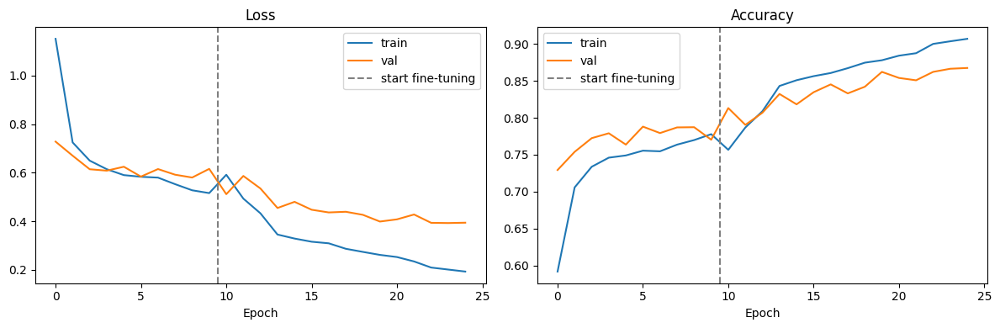

In [ ]:
h1 = pd.read_csv(f'{DRIVE_DIR}/tl_head_history.csv')
h2 = pd.read_csv(f'{DRIVE_DIR}/tl_finetune_history.csv')
hh = pd.concat([h1, h2], ignore_index=True)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (tr, va, title) in zip(ax, [('loss', 'val_loss', 'Loss'),
                                   ('accuracy', 'val_accuracy', 'Accuracy')]):
    a.plot(hh[tr], label='train'); a.plot(hh[va], label='val')
    a.axvline(len(h1) - 0.5, color='gray', linestyle='--', label='start fine-tuning')
    a.set_title(title); a.set_xlabel('Epoch'); a.legend()
plt.tight_layout()
plt.savefig(f'{DRIVE_DIR}/figures/mobilenetv2_curves.png', dpi=200)
plt.show()

Interpretation: After the switch to fine-tuning, validation loss falls from about 0.6 to about 0.4 and validation accuracy climbs from about 0.78 to 0.87. A train/validation gap opens (accuracy about 0.91 against 0.87, loss about 0.19 against 0.39): before the switch the model was underfitting, afterwards it shows mild overfitting, a shift from high bias towards higher variance that is still far smaller than the Random Forest's (0.99 against 0.70). Validation loss flattens from about epoch 22 while training loss keeps falling. Because fine-tuning restarted from the epoch-9 head checkpoint, the curve is not perfectly continuous at the dashed line.

## 8. Error analysis and ablations on the validation set

### Confusion matrix, top confusions and crop-level errors (fine-tuned MobileNetV2)

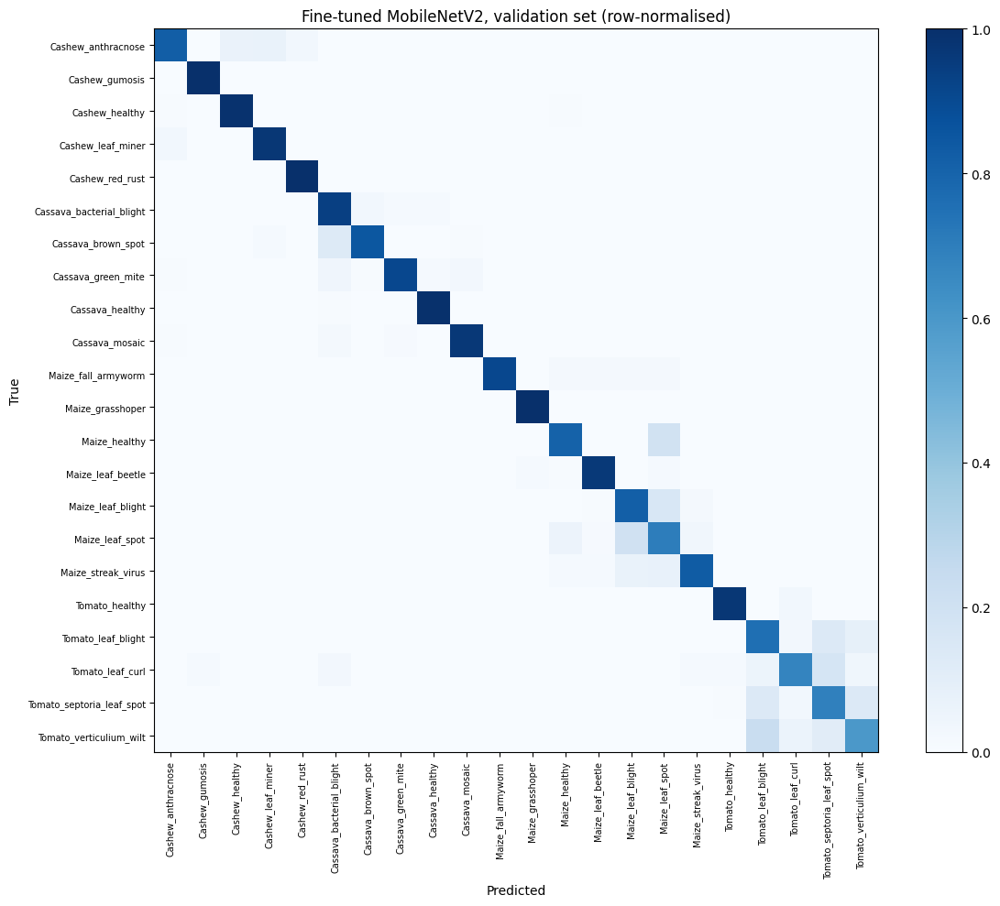

  56  Tomato_septoria_leaf_spot  ->  Tomato_verticulium_wilt
  56  Tomato_septoria_leaf_spot  ->  Tomato_leaf_blight
  37  Maize_leaf_spot  ->  Maize_leaf_blight
  29  Cassava_brown_spot  ->  Cassava_bacterial_blight
  27  Tomato_verticulium_wilt  ->  Tomato_leaf_blight
  26  Tomato_leaf_blight  ->  Tomato_septoria_leaf_spot
  23  Maize_leaf_blight  ->  Maize_leaf_spot
  18  Cashew_anthracnose  ->  Cashew_leaf_miner
  17  Cashew_anthracnose  ->  Cashew_healthy
  16  Tomato_leaf_blight  ->  Tomato_verticulium_wilt
  13  Tomato_verticulium_wilt  ->  Tomato_septoria_leaf_spot
  13  Tomato_leaf_curl  ->  Tomato_septoria_leaf_spot
Errors: 504 | cross-crop: 17 (3.4%)
Crop-level accuracy: 0.995


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_val_true, pred_ft)
cm_norm = cm / cm.sum(1, keepdims=True)

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(class_names, rotation=90, fontsize=7)
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(class_names, fontsize=7)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Fine-tuned MobileNetV2, validation set (row-normalised)')
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig(f'{DRIVE_DIR}/figures/cm_mobilenetv2_ft_val.png', dpi=200)
plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted(((off[i, j], class_names[i], class_names[j])
                for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if off[i, j] > 0),
               reverse=True)[:12]
for n, t, p in pairs:
    print(f'{n:4d}  {t}  ->  {p}')

crop_of = {i: c.split('_')[0] for i, c in enumerate(class_names)}
true_crop = np.array([crop_of[i] for i in y_val_true])
pred_crop = np.array([crop_of[i] for i in pred_ft])
wrong = pred_ft != y_val_true
cross = true_crop != pred_crop
print('Errors:', wrong.sum(), '| cross-crop: %d (%.1f%%)' % (cross.sum(), 100 * cross.sum() / wrong.sum()))
print('Crop-level accuracy: %.3f' % (true_crop == pred_crop).mean())

The fine-tuned model makes 504 errors on the validation set, of which only 17 (3.4%) cross crop boundaries; crop-level accuracy is 0.995. For the baseline Random Forest the figures were 40.1% and 0.863. The deep model has essentially solved "which crop is this", so its remaining errors are about telling conditions apart within a crop. Tomato dominates: seven of the twelve most frequent confusions are tomato pairs. The confusion is asymmetric: `Tomato_septoria_leaf_spot` is sent to `Tomato_verticulium_wilt` (56) and `Tomato_leaf_blight` (56), but only 13 wilt images go the other way. Maize has one mutual pair (leaf spot and leaf blight, 37 and 23).

### Inspecting misclassified images
`show_errors` displays validation images of one true class that were predicted as another, to check whether the errors come from genuinely overlapping symptoms, image quality or labelling.

56 images: Tomato_septoria_leaf_spot -> Tomato_verticulium_wilt


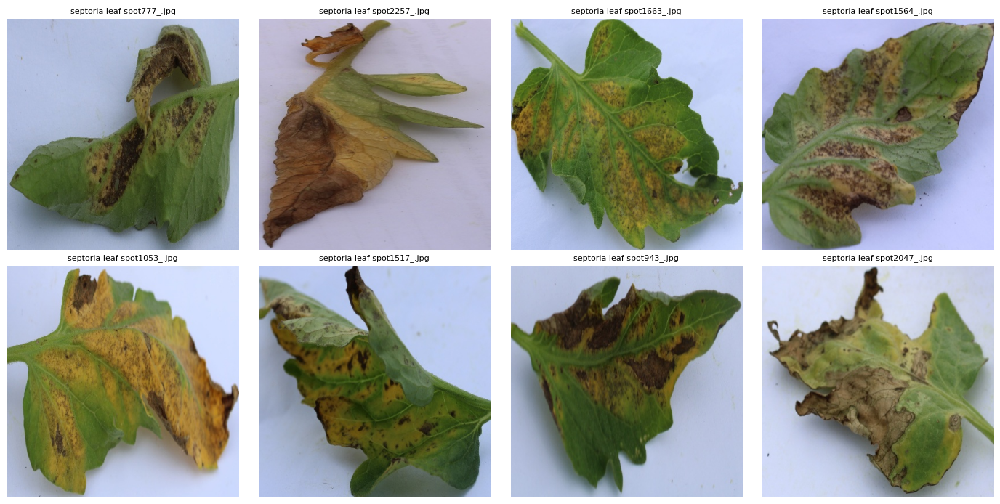

In [ ]:
def show_errors(true_name, pred_name, n=8):
    t, p = class_names.index(true_name), class_names.index(pred_name)
    idx = np.where((y_val_true == t) & (pred_ft == p))[0]
    print(len(idx), 'images:', true_name, '->', pred_name)
    pick = np.random.RandomState(SEED).choice(idx, size=min(n, len(idx)), replace=False)
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for ax, i in zip(axes.ravel(), pick):
        ax.imshow(cv2.cvtColor(cv2.imread(val_df['path'].iloc[i]), cv2.COLOR_BGR2RGB))
        ax.set_title(os.path.basename(val_df['path'].iloc[i]), fontsize=8)
        ax.axis('off')
    plt.tight_layout()
    plt.savefig(f'{DRIVE_DIR}/figures/err_{true_name}_to_{pred_name}.png', dpi=200, bbox_inches='tight')
    plt.show()

show_errors('Tomato_septoria_leaf_spot', 'Tomato_verticulium_wilt')

**Observation.** The photos of septoria images predicted as verticulium wilt are sharp and well lit, so image quality does not explain the errors. Many show severe, advanced damage (large yellow-brown or dead areas) instead of distinct spots, and some verticulium wilt images are also severely damaged. One hypothesis is that the two classes overlap at advanced disease stages, where whole leaves are dying and a label records the cause while the photo shows only how bad the leaf looks. This is a hypothesis from a small sample and has not been tested statistically.

### ROC and precision-recall curves
Per-class ROC-AUC and average precision (one-vs-rest) for the fine-tuned model, with curves for the six weakest classes.

macro ROC-AUC (one-vs-rest): 0.9946
macro average precision:     0.9128
                    class   auc  avg_precision  support
  Tomato_verticulium_wilt 0.976          0.593      116
         Tomato_leaf_curl 0.988          0.742       77
            Maize_healthy 0.998          0.762       31
          Maize_leaf_spot 0.988          0.787      188
       Tomato_leaf_blight 0.981          0.792      194
        Maize_leaf_blight 0.992          0.839      150
Tomato_septoria_leaf_spot 0.985          0.887      411
       Cashew_anthracnose 0.991          0.938      259
       Maize_streak_virus 0.996          0.944      146
       Cassava_brown_spot 0.997          0.961      222
        Cashew_leaf_miner 0.996          0.962      206
 Cassava_bacterial_blight 0.997          0.974      392
       Cassava_green_mite 0.999          0.974      152
      Maize_fall_armyworm 0.999          0.978       43
           Cashew_healthy 0.996          0.980      205
           Tomato_healthy 1.000 

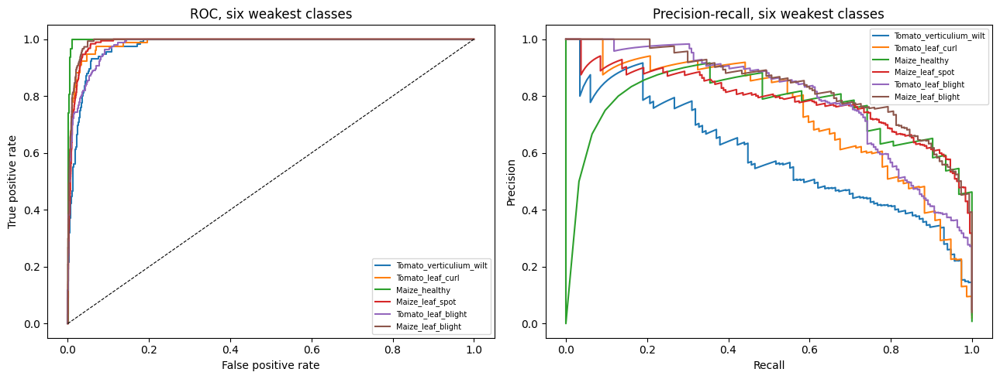

In [ ]:
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             roc_curve, precision_recall_curve)
from sklearn.preprocessing import label_binarize

Y = label_binarize(y_val_true, classes=np.arange(NUM_CLASSES))
print('macro ROC-AUC (one-vs-rest): %.4f' % roc_auc_score(Y, probs_val_ft, average='macro'))
print('macro average precision:     %.4f' % average_precision_score(Y, probs_val_ft, average='macro'))

per = pd.DataFrame({
    'class': class_names,
    'auc': [roc_auc_score(Y[:, k], probs_val_ft[:, k]) for k in range(NUM_CLASSES)],
    'avg_precision': [average_precision_score(Y[:, k], probs_val_ft[:, k]) for k in range(NUM_CLASSES)],
    'support': Y.sum(0)}).sort_values('avg_precision')
print(per.round(3).to_string(index=False))

weak = per.head(6)['class'].tolist()
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for c in weak:
    k = class_names.index(c)
    fpr, tpr, _ = roc_curve(Y[:, k], probs_val_ft[:, k]); ax[0].plot(fpr, tpr, label=c)
    pr, rc, _ = precision_recall_curve(Y[:, k], probs_val_ft[:, k]); ax[1].plot(rc, pr, label=c)
ax[0].plot([0, 1], [0, 1], 'k--', lw=0.8)
ax[0].set_title('ROC, six weakest classes'); ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate')
ax[1].set_title('Precision-recall, six weakest classes'); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision')
ax[0].legend(fontsize=7); ax[1].legend(fontsize=7)
plt.tight_layout()
plt.savefig(f'{DRIVE_DIR}/figures/roc_pr_mobilenetv2_ft_val.png', dpi=200, bbox_inches='tight')
plt.show()

Macro ROC-AUC is 0.9946 but macro average precision is only 0.9128. For the weakest class, `Tomato_verticulium_wilt`, AUC is 0.976 but average precision is 0.593 (chance level is about 0.03). One-vs-rest ROC is dominated by the many easy negatives, so it looks excellent even for poor classes, while precision-recall responds directly to false positives and is more informative under class imbalance. The classes ranked weakest by average precision (wilt, leaf curl, `Maize_healthy`, `Maize_leaf_spot`, `Tomato_leaf_blight`, `Maize_leaf_blight`) agree with the F1 ranking. In an application, the precision-recall curve is what allows choosing an operating threshold, depending on whether a missed disease or a false alarm is costlier.

### Correctly classified examples for comparison
The same function applied to correctly classified images of the two confused classes, to compare them with the errors above.

69 images: Tomato_verticulium_wilt -> Tomato_verticulium_wilt


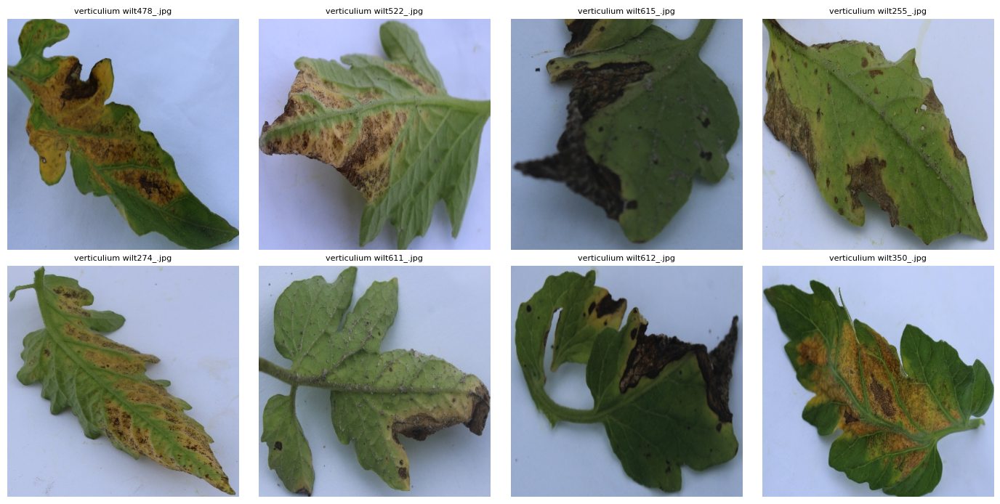

283 images: Tomato_septoria_leaf_spot -> Tomato_septoria_leaf_spot


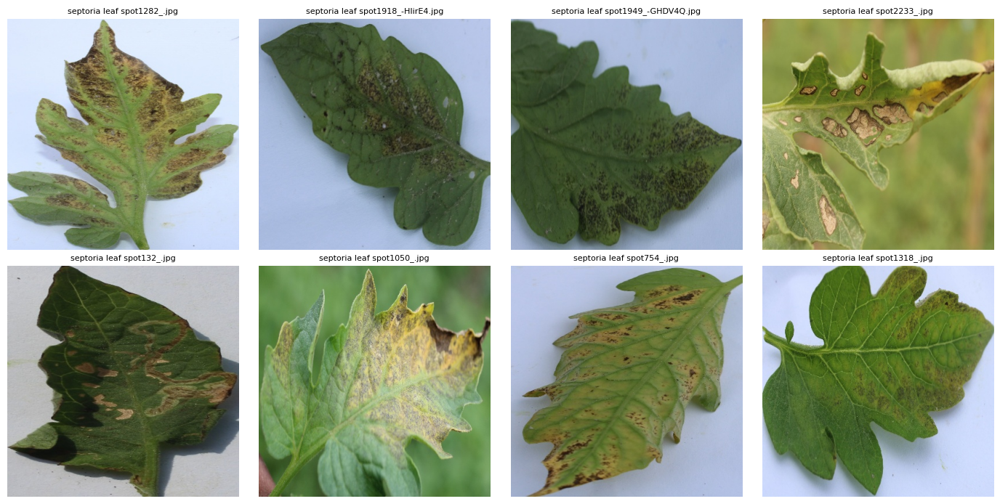

In [ ]:
show_errors('Tomato_verticulium_wilt', 'Tomato_verticulium_wilt')
show_errors('Tomato_septoria_leaf_spot', 'Tomato_septoria_leaf_spot')

### Ablation: class weights
This tests whether class weights explain the recall-over-precision pattern seen in the CNN and the frozen head. The two-stage MobileNetV2 procedure (head, then fine-tune) is wrapped in one reusable function so that a setting can be changed in one place; results are appended to `dl_results.csv`.

In [ ]:
from tensorflow.keras import layers
DL_RESULTS_CSV = f'{DRIVE_DIR}/dl_results.csv'

def build_mobilenet(seed):
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)
    base = keras.applications.MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet')
    base.trainable = False
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='image')
    x = layers.RandomFlip('horizontal_and_vertical')(inputs)
    x = layers.RandomRotation(0.1)(x)
    x = layers.RandomZoom(0.1)(x)
    x = layers.RandomContrast(0.1)(x)
    x = layers.Rescaling(1. / 127.5, offset=-1)(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return keras.Model(inputs, outputs)

def make_callbacks(run):
    return [
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2),
        keras.callbacks.ModelCheckpoint(f'{MODEL_DIR}/{run}_best.keras',
                                        monitor='val_loss', save_best_only=True),
        tb_callback(run),
    ]

def val_scores(path):
    m = keras.models.load_model(path)
    pred = m.predict(val_ds, verbose=0).argmax(1)
    return (round(accuracy_score(y_val_true, pred), 4),
            round(f1_score(y_val_true, pred, average='macro'), 4))

def run_two_stage(prefix, seed=SEED, use_class_weight=True, freeze_until=100,
                  head_epochs=10, ft_epochs=15, ft_lr=5e-5):
    cw = class_weight if use_class_weight else None
    t0 = time.time()

    model = build_mobilenet(seed)
    model.compile(keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    model.fit(train_ds, validation_data=val_ds, epochs=head_epochs,
              class_weight=cw, callbacks=make_callbacks(f'{prefix}_head'), verbose=2)

    model = keras.models.load_model(f'{MODEL_DIR}/{prefix}_head_best.keras')
    base = model.get_layer('mobilenetv2_1.00_224')
    base.trainable = True
    for i, layer in enumerate(base.layers):
        layer.trainable = (i >= freeze_until) and not isinstance(layer, layers.BatchNormalization)
    model.compile(keras.optimizers.Adam(ft_lr),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    model.fit(train_ds, validation_data=val_ds, epochs=ft_epochs,
              class_weight=cw, callbacks=make_callbacks(f'{prefix}_finetune'), verbose=2)

    head_acc, head_f1 = val_scores(f'{MODEL_DIR}/{prefix}_head_best.keras')
    ft_acc, ft_f1 = val_scores(f'{MODEL_DIR}/{prefix}_finetune_best.keras')
    row = {'run': prefix, 'seed': seed, 'class_weight': use_class_weight,
           'freeze_until': freeze_until, 'ft_lr': ft_lr,
           'head_val_acc': head_acc, 'head_val_f1': head_f1,
           'ft_val_acc': ft_acc, 'ft_val_f1': ft_f1,
           'minutes': round((time.time() - t0) / 60, 1)}
    old = pd.read_csv(DL_RESULTS_CSV) if os.path.exists(DL_RESULTS_CSV) else pd.DataFrame()
    pd.concat([old, pd.DataFrame([row])], ignore_index=True).to_csv(DL_RESULTS_CSV, index=False)
    return row

**Run without class weights** (everything else identical to the weighted runs):

In [ ]:
run_two_stage('dl_mobilenetv2_noCW', seed=SEED, use_class_weight=False)

Epoch 1/10
551/551 - 49s - 90ms/step - accuracy: 0.6276 - loss: 1.1325 - val_accuracy: 0.7661 - val_loss: 0.6579 - learning_rate: 0.0010
Epoch 2/10
551/551 - 38s - 68ms/step - accuracy: 0.7376 - loss: 0.7414 - val_accuracy: 0.7812 - val_loss: 0.6047 - learning_rate: 0.0010
Epoch 3/10
551/551 - 39s - 72ms/step - accuracy: 0.7594 - loss: 0.6756 - val_accuracy: 0.7735 - val_loss: 0.6242 - learning_rate: 0.0010
Epoch 4/10
551/551 - 40s - 72ms/step - accuracy: 0.7646 - loss: 0.6381 - val_accuracy: 0.8000 - val_loss: 0.5553 - learning_rate: 0.0010
Epoch 5/10
551/551 - 38s - 70ms/step - accuracy: 0.7753 - loss: 0.6181 - val_accuracy: 0.7923 - val_loss: 0.5753 - learning_rate: 0.0010
Epoch 6/10
551/551 - 40s - 73ms/step - accuracy: 0.7786 - loss: 0.6155 - val_accuracy: 0.8008 - val_loss: 0.5528 - learning_rate: 0.0010
Epoch 7/10
551/551 - 39s - 71ms/step - accuracy: 0.7819 - loss: 0.5978 - val_accuracy: 0.8008 - val_loss: 0.5441 - learning_rate: 0.0010
Epoch 8/10
551/551 - 39s - 70ms/step - ac

{'run': 'dl_mobilenetv2_noCW',
 'seed': 42,
 'class_weight': False,
 'freeze_until': 100,
 'ft_lr': 5e-05,
 'head_val_acc': 0.8045,
 'head_val_f1': 0.7955,
 'ft_val_acc': 0.8763,
 'ft_val_f1': 0.8684,
 'minutes': 16.8}

Without class weights the frozen-head model reaches validation accuracy 0.805 and macro-F1 0.796 (weighted: 0.787 and 0.790), and the fine-tuned model reaches 0.876 and 0.868 (weighted: 0.867 and 0.864). Early stopping ended fine-tuning at epoch 12 with the best checkpoint at epoch 8; the two stages took 16.8 minutes. The differences in overall scores (about one point) are within the run-to-run variation measured for the CNN, so class weighting made no clear difference to overall performance.

**Precision and recall with and without class weights.**

In [ ]:
from sklearn.metrics import precision_score, recall_score

def summary(pred):
    return {'acc': accuracy_score(y_val_true, pred),
            'macro_f1': f1_score(y_val_true, pred, average='macro'),
            'macro_precision': precision_score(y_val_true, pred, average='macro'),
            'macro_recall': recall_score(y_val_true, pred, average='macro')}

def preds(path):
    return keras.models.load_model(path).predict(val_ds, verbose=0).argmax(1)

pred_head_cw   = pred_tl
pred_head_nocw = preds(f'{MODEL_DIR}/dl_mobilenetv2_noCW_head_best.keras')
pred_ft_cw     = pred_ft
pred_ft_nocw   = preds(f'{MODEL_DIR}/dl_mobilenetv2_noCW_finetune_best.keras')

print(pd.DataFrame({'head, class weights': summary(pred_head_cw),
                    'head, no weights':    summary(pred_head_nocw),
                    'fine-tuned, class weights': summary(pred_ft_cw),
                    'fine-tuned, no weights':    summary(pred_ft_nocw)}).T.round(4))

rep = lambda p: classification_report(y_val_true, p, target_names=class_names, output_dict=True)
r_cw, r_no = rep(pred_ft_cw), rep(pred_ft_nocw)
focus = ['Tomato_verticulium_wilt', 'Tomato_leaf_curl', 'Tomato_leaf_blight',
         'Tomato_septoria_leaf_spot', 'Maize_healthy']
print(pd.DataFrame({c: {'P with': r_cw[c]['precision'], 'R with': r_cw[c]['recall'],
                        'P without': r_no[c]['precision'], 'R without': r_no[c]['recall']}
                    for c in focus}).T.round(3))

                              acc  macro_f1  macro_precision  macro_recall
head, class weights        0.7873    0.7897           0.7903        0.8226
head, no weights           0.8045    0.7955           0.8209        0.7975
fine-tuned, class weights  0.8665    0.8638           0.8616        0.8709
fine-tuned, no weights     0.8763    0.8684           0.8693        0.8713
                           P with  R with  P without  R without
Tomato_verticulium_wilt     0.476   0.595      0.523      0.491
Tomato_leaf_curl            0.658   0.675      0.770      0.610
Tomato_leaf_blight          0.628   0.758      0.693      0.686
Tomato_septoria_leaf_spot   0.842   0.689      0.788      0.825
Maize_healthy               0.610   0.806      0.675      0.871


Interpretation: Class weights change *where* errors fall more than *how many* there are. In the frozen-head stage, weights tilt the model towards recall (macro recall 0.823 against precision 0.790); without them the balance flips (0.798 against 0.821). After fine-tuning the effect mostly disappears (precision and recall within one point of each other in both versions). Per class, weights raise recall of the rare tomato diseases at the cost of precision (`Tomato_verticulium_wilt` recall 0.595 against 0.491 without weights, precision 0.476 against 0.523) and lower the recall of the largest tomato class (`Tomato_septoria_leaf_spot` 0.689 against 0.825). Which setting is preferable depends on the cost of missed diseases against false alarms. Each setting was run once, so these are indications, not established effects.

### TensorBoard viewer
Opens the logged runs (classical-ML results, both CNN runs, MobileNetV2 stages) in Colab. This output is interactive and does not render outside Colab; screenshots of the dashboard are in the report.

In [ ]:
%load_ext tensorboard
%tensorboard --logdir /content/drive/MyDrive/ccmt_project/tb_logs

<IPython.core.display.Javascript object>

### Application view: healthy against diseased
For a screening tool, the exact class matters less than whether a diseased plant is flagged. Treating any class containing "healthy" as healthy, this cell computes disease recall (diseased images flagged as diseased), the false-alarm rate (healthy images flagged as diseased) and exact-class accuracy.

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

is_healthy = np.array(['healthy' in c.lower() for c in class_names])

def screen_metrics(pred, y_true=y_val_true):
    t_dis, p_dis = ~is_healthy[y_true], ~is_healthy[pred]
    return {
        'disease recall (diseased flagged as diseased)': (p_dis & t_dis).sum() / t_dis.sum(),
        'false-alarm rate (healthy flagged as diseased)': (p_dis & ~t_dis).sum() / (~t_dis).sum(),
        'exact-class accuracy': (pred == y_true).mean(),
    }

pred_cw   = pred_ft_cw
pred_nocw = pred_ft_nocw

print(pd.DataFrame({'class weights': screen_metrics(pred_cw),
                    'no weights':    screen_metrics(pred_nocw)}).round(4))

rare = ['Tomato_verticulium_wilt', 'Tomato_leaf_curl', 'Tomato_leaf_blight']
rep = classification_report(y_val_true, pred_cw, target_names=class_names, output_dict=True)
print({c: round(rep[c]['recall'], 3) for c in rare})

                                                class weights  no weights
disease recall (diseased flagged as diseased)          0.9872      0.9891
false-alarm rate (healthy flagged as diseased)         0.0206      0.0206
exact-class accuracy                                   0.8665      0.8763
{'Tomato_verticulium_wilt': 0.595, 'Tomato_leaf_curl': 0.675, 'Tomato_leaf_blight': 0.758}


On the validation set both fine-tuned variants flag about 99% of diseased images as diseased (0.987 with class weights, 0.989 without) and raise a false alarm on about 2% of healthy images (0.0206 for both), even though their exact-class accuracies differ (0.867 and 0.876). At the screening level the two variants behave almost identically. For the weighted model, recall for the rare tomato diseases is 0.595 (verticulium wilt), 0.675 (leaf curl) and 0.758 (leaf blight).

## 9. Final evaluation on the test set and saved models

### Test-set evaluation
The two finalists were fixed from validation results *before* looking at the test set, using one rule: the highest validation macro-F1 within each family. They are the tuned Random Forest and the fine-tuned MobileNetV2 without class weights (validation macro-F1 0.685 and 0.868). The test set is evaluated once for these models, which gives an estimate not influenced by model selection.

             accuracy  macro_f1  macro_ROC_AUC (OvR)  macro_avg_precision  \
RF tuned       0.7007    0.6852               0.9718               0.7311   
MobileNetV2    0.8721    0.8650               0.9948               0.9159   

             disease recall (diseased flagged as diseased)  \
RF tuned                                            0.9802   
MobileNetV2                                         0.9866   

             false-alarm rate (healthy flagged as diseased)  \
RF tuned                                             0.2433   
MobileNetV2                                          0.0515   

             exact-class accuracy  
RF tuned                   0.7007  
MobileNetV2                0.8721  
                           precision    recall  f1-score   support

       Cashew_anthracnose      0.950     0.885     0.916       260
           Cashew_gumosis      1.000     0.983     0.991        59
           Cashew_healthy      0.948     0.976     0.962       205
        Cashew

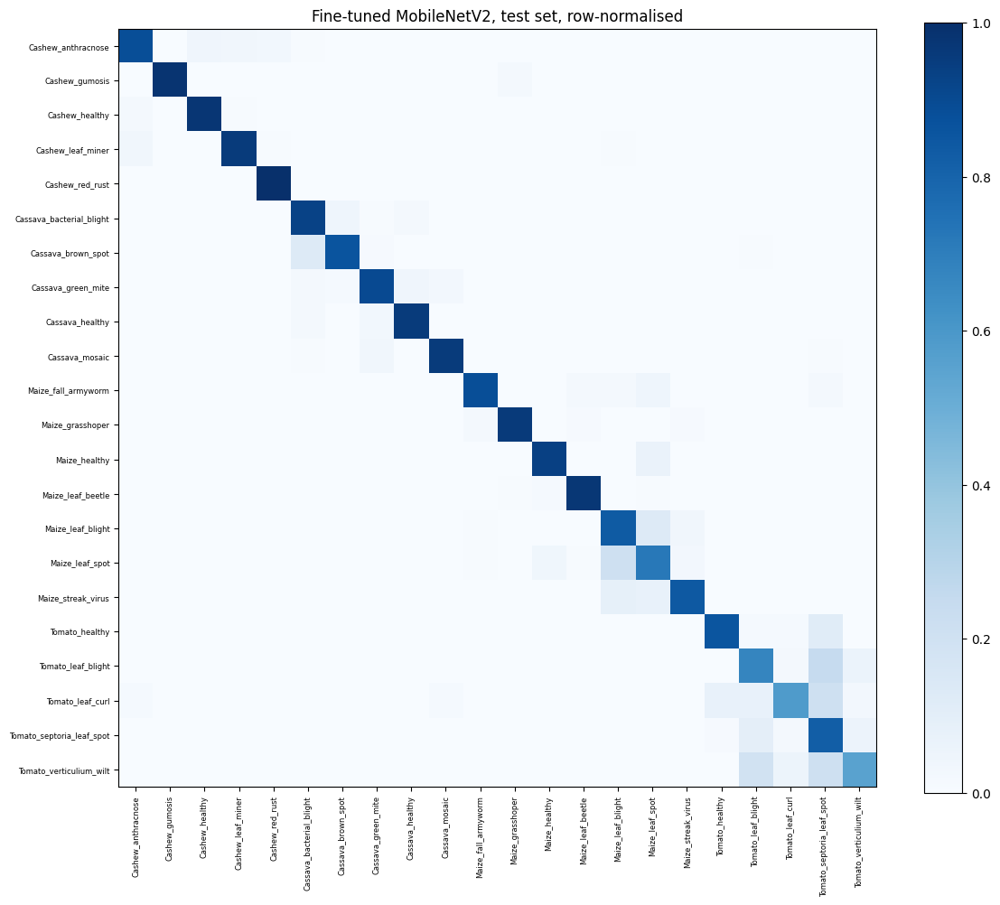

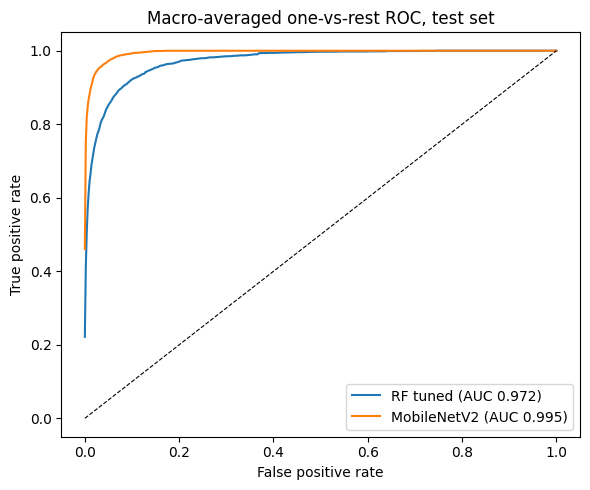

Tomato_leaf_blight           0.976
Tomato_verticulium_wilt      0.979
Tomato_septoria_leaf_spot    0.983
Tomato_leaf_curl             0.984
Maize_leaf_spot              0.992
dtype: float64


In [ ]:
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix,
                             roc_auc_score, average_precision_score, roc_curve)
from sklearn.preprocessing import label_binarize

y_test_true = test_df['y'].values
Y_test = label_binarize(y_test_true, classes=np.arange(NUM_CLASSES))

rf_tuned = joblib.load(f'{MODEL_DIR}/baseline_random_forest_tuned.joblib')
mnet     = keras.models.load_model(f'{MODEL_DIR}/dl_mobilenetv2_noCW_finetune_best.keras')

probs = {
    'RF tuned':    rf_tuned.predict_proba(X_test),
    'MobileNetV2': mnet.predict(test_ds, verbose=0),
}
for name, p in probs.items():
    assert p.shape == (len(y_test_true), NUM_CLASSES), name

rows = {}
for name, p in probs.items():
    pred = p.argmax(1)
    rows[name] = {
        'accuracy':             accuracy_score(y_test_true, pred),
        'macro_f1':             f1_score(y_test_true, pred, average='macro'),
        'macro_ROC_AUC (OvR)':  roc_auc_score(Y_test, p, average='macro'),
        'macro_avg_precision':  average_precision_score(Y_test, p, average='macro'),
        **screen_metrics(pred, y_test_true),
    }
test_table = pd.DataFrame(rows).T.round(4)
print(test_table)
test_table.to_csv(f'{DRIVE_DIR}/test_results.csv')

pred_main = probs['MobileNetV2'].argmax(1)
print(classification_report(y_test_true, pred_main, target_names=class_names, digits=3))

cm = confusion_matrix(y_test_true, pred_main, normalize='true')
plt.figure(figsize=(12, 10))
plt.imshow(cm, cmap='Blues'); plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90, fontsize=6)
plt.yticks(range(NUM_CLASSES), class_names, fontsize=6)
plt.title('Fine-tuned MobileNetV2, test set, row-normalised')
plt.tight_layout()
plt.savefig(f'{DRIVE_DIR}/figures/cm_mobilenetv2_test.png', dpi=200)
plt.show()

grid = np.linspace(0, 1, 500)
plt.figure(figsize=(6, 5))
for name, p in probs.items():
    tprs = []
    for c in range(NUM_CLASSES):
        fpr, tpr, _ = roc_curve(Y_test[:, c], p[:, c])
        tprs.append(np.interp(grid, fpr, tpr))
    plt.plot(grid, np.mean(tprs, axis=0),
             label=f"{name} (AUC {rows[name]['macro_ROC_AUC (OvR)']:.3f})")
plt.plot([0, 1], [0, 1], 'k--', lw=0.8)
plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title('Macro-averaged one-vs-rest ROC, test set')
plt.legend(); plt.tight_layout()
plt.savefig(f'{DRIVE_DIR}/figures/roc_test_both.png', dpi=200)
plt.show()

per_class_auc = pd.Series([roc_auc_score(Y_test[:, c], probs['MobileNetV2'][:, c])
                           for c in range(NUM_CLASSES)], index=class_names)
print(per_class_auc.sort_values().head(5).round(3))

On the test set the tuned Random Forest reaches accuracy 0.701 and macro-F1 0.685, and the fine-tuned MobileNetV2 reaches accuracy 0.872 and macro-F1 0.865. Both are very close to their validation scores (0.685 and 0.868), so model selection on the validation set introduced little optimism. The deep model is about 18 points higher in macro-F1, and has a higher macro ROC-AUC (0.995 against 0.972) and a much higher macro average precision (0.916 against 0.731). The screening view shows similar disease recall (0.987 against 0.980) but a false-alarm rate of 5.2% for MobileNetV2 against 24.3% for the Random Forest. The comparison is not like-for-like: MobileNetV2 uses 224×224 images and ImageNet pretraining, while the Random Forest uses hand-crafted features from 128×128 images, so part of the gap comes from transfer learning and not only from learned features. The weakest test classes for MobileNetV2 are again tomato (`Tomato_leaf_blight` F1 0.662, `Tomato_leaf_curl` 0.643) and the maize leaf spot/blight pair (0.756 and 0.761).

### Save the final models
The best traditional model (`.joblib`) and best deep model (`.keras` and TensorFlow SavedModel), together with a class-index mapping so that predictions can be decoded, are copied to `final_models/` in the shared Drive folder.

In [ ]:
FINAL_DIR = f'{DRIVE_DIR}/final_models'
os.makedirs(FINAL_DIR, exist_ok=True)

shutil.copy(f'{MODEL_DIR}/baseline_random_forest_tuned.joblib',
            f'{FINAL_DIR}/best_traditional_random_forest_tuned.joblib')
shutil.copy(f'{MODEL_DIR}/dl_mobilenetv2_noCW_finetune_best.keras',
            f'{FINAL_DIR}/best_deep_mobilenetv2_finetuned.keras')

json.dump({i: c for i, c in enumerate(class_names)},
          open(f'{FINAL_DIR}/class_names.json', 'w'), indent=2)

m = keras.models.load_model(f'{FINAL_DIR}/best_deep_mobilenetv2_finetuned.keras')
m.export(f'{FINAL_DIR}/best_deep_mobilenetv2_savedmodel')

for f in sorted(os.listdir(FINAL_DIR)):
    p = f'{FINAL_DIR}/{f}'
    size = (sum(os.path.getsize(os.path.join(r, x)) for r, _, fs in os.walk(p) for x in fs)
            if os.path.isdir(p) else os.path.getsize(p))
    print(f'{f:50s} {size/1e6:8.1f} MB')

Saved artifact at '/content/drive/MyDrive/ccmt_project/final_models/best_deep_mobilenetv2_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 22), dtype=tf.float32, name=None)
Captures:
  133642808441744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133642808441936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133642808441552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133642808441360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133642808439632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133642808430800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133642808430992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133642808427152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133642808439824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133642808439440: TensorSp

## 10. Experiment table
All experiments in one table: model, settings, training and validation accuracy, validation macro-F1, training time and, for the two finalists, test results. The split is the same for every run (stratified 70/15/15, seed 42). `gap_train_val` is the difference between training and validation accuracy, used as an indicator of variance. For the deep models, training accuracy here is re-computed on the unaugmented training images, so it is not comparable with the training accuracy printed during Keras training (which is measured with augmentation and dropout active). The `observations` column explains why each result differs from the previous ones. Logs for every run are in `tb_logs/` on Drive (the classical-ML runs and CNN run 1 were logged after the fact, as described in Section 7.4).

In [ ]:
val_ds        = make_ds(val_df,   'val')
train_eval_ds = make_ds(train_df, 'train')
y_train_true  = train_df['y'].values

SPLIT = 'stratified 70/15/15, seed 42'

ml = pd.read_csv(f'{DRIVE_DIR}/ml_baseline_results.csv').set_index('model')
ml_rows = [
    ('logreg',              'Logistic Regression', 'C=1, balanced, max_iter=500'),
    ('logreg_C0.001',       'Logistic Regression', 'C=0.001, balanced'),
    ('logreg_C0.01',        'Logistic Regression', 'C=0.01, balanced'),
    ('logreg_C0.1',         'Logistic Regression', 'C=0.1, balanced'),
    ('svm_rbf',             'SVM (RBF)',           'C=1, gamma=scale, balanced'),
    ('random_forest',       'Random Forest',       '300 trees, max_features=sqrt, balanced'),
    ('random_forest_tuned', 'Random Forest (tuned)',
        '300 trees, min_samples_leaf=4, max_features=0.05, max_depth=None, balanced '
        '(10-config randomized search, 100 trees)'),
]
table = []
for key, family, hp in ml_rows:
    r = ml.loc[key]
    table.append({'paradigm': 'Traditional ML', 'model': family, 'settings': hp,
                  'train_acc': r['train_acc'], 'val_acc': r['val_acc'],
                  'val_macro_f1': r['val_macro_f1'],
                  'train_min': round(r['fit_seconds'] / 60, 1), 'key': key})

def eval_model(fname):
    m = keras.models.load_model(f'{MODEL_DIR}/{fname}')
    tr = m.predict(train_eval_ds, verbose=0).argmax(1)
    va = m.predict(val_ds, verbose=0).argmax(1)
    return (accuracy_score(y_train_true, tr), accuracy_score(y_val_true, va),
            f1_score(y_val_true, va, average='macro'))

dl_rows = [
    ('CNN baseline (run 2)', 'cnn_baseline_run2.keras',
     '4 conv blocks 32-64-128-128, Adam 1e-3, 30 ep max, dropout 0.4/0.3, balanced, augmentation', 38),
    ('MobileNetV2, frozen head, class weights', 'tl_head_best.keras',
     'ImageNet base frozen, Adam 1e-3, 10 ep max, dropout 0.3, balanced', 7),
    ('MobileNetV2, fine-tuned, class weights', 'tl_finetune_best.keras',
     'unfreeze from layer 100 (BN frozen), Adam 5e-5, 15 ep max, balanced', 12),
    ('MobileNetV2, frozen head, no weights', 'dl_mobilenetv2_noCW_head_best.keras',
     'as head stage above, no class weights', None),
    ('MobileNetV2, fine-tuned, no weights', 'dl_mobilenetv2_noCW_finetune_best.keras',
     'as fine-tune above, no class weights (both stages 16.8 min)', 16.8),
]
for name, fname, hp, mins in dl_rows:
    tr, va, f1 = eval_model(fname)
    table.append({'paradigm': 'Deep learning', 'model': name, 'settings': hp,
                  'train_acc': round(tr, 4), 'val_acc': round(va, 4),
                  'val_macro_f1': round(f1, 4), 'train_min': mins, 'key': fname})

exp = pd.DataFrame(table)

test = pd.read_csv(f'{DRIVE_DIR}/test_results.csv', index_col=0)
exp['test_acc'] = np.nan; exp['test_macro_f1'] = np.nan
fin = {'random_forest_tuned': 'RF tuned',
       'dl_mobilenetv2_noCW_finetune_best.keras': 'MobileNetV2'}
for k, t in fin.items():
    exp.loc[exp['key'] == k, ['test_acc', 'test_macro_f1']] = test.loc[t, ['accuracy', 'macro_f1']].values

exp['gap_train_val'] = (exp['train_acc'] - exp['val_acc']).round(3)
exp['observations'] = ''
exp.insert(0, 'id', range(1, len(exp) + 1))
exp.drop(columns='key').to_csv(f'{DRIVE_DIR}/experiment_table.csv', index=False)
exp.drop(columns=['key', 'settings']).round(4)

,id,paradigm,model,train_acc,val_acc,val_macro_f1,train_min,test_acc,test_macro_f1,gap_train_val,observations
0,1,Traditional ML,Logistic Regression,0.9888,0.5285,0.5060,3.0,NaN,NaN,0.460,
1,2,Traditional ML,Logistic Regression,0.6355,0.5126,0.5040,1.5,NaN,NaN,0.123,
2,3,Traditional ML,Logistic Regression,0.7826,0.5385,0.5248,2.5,NaN,NaN,0.244,
3,4,Traditional ML,Logistic Regression,0.9149,0.5412,0.5234,3.3,NaN,NaN,0.374,
4,5,Traditional ML,SVM (RBF),0.8953,0.5984,0.5934,11.3,NaN,NaN,0.297,
5,6,Traditional ML,Random Forest,0.9939,0.6575,0.6379,7.4,NaN,NaN,0.336,
6,7,Traditional ML,Random Forest (tuned),0.9917,0.6967,0.6849,16.5,0.7007,0.6852,0.295,
7,8,Deep learning,CNN baseline (run 2),0.7184,0.6977,0.6959,38.0,NaN,NaN,0.021,
8,9,Deep learning,"MobileNetV2, frozen head, class weights",0.8117,0.7873,0.7897,7.0,NaN,NaN,0.024,
9,10,Deep learning,"MobileNetV2, fine-tuned, class weights",0.9215,0.8665,0.8638,12.0,NaN,NaN,0.055,
